# Insol Prediction for PCC Cement (Mill CM01)

Predict the daily **Insol** (insoluble residue, %) of Portland Composite Cement from its chemical
composition (oxides), fineness (Blaine) and lagged values, using a strictly time-aware workflow.

**Pipeline**

| # | Section | What happens |
|---|---------|--------------|
| 1 | Setup | imports, paths, constants |
| 2 | Helper functions | everything reusable lives here |
| 3 | Load & clean | rebuild dates, clean values, domain rules |
| 4 | Split & impute | chronological 80/20 split, KNN imputation fitted on train only |
| 5 | EDA | distributions, correlation, VIF, seasonality, ACF |
| 6 | Features & model selection | lag features, `TimeSeriesSplit` comparison of 9 models |
| 7 | Test evaluation | chosen model vs. baselines, residual bias by month |
| 8 | Residual correction (EWMA) | span chosen by CV, evaluated on test |
| 9 | Tuning + improved correction | Ridge/Lasso/ElasticNet tuning, out-of-fold residuals, significance tests |
| 10 | Extra experiments | Insol lags, periodic retraining, Huber |
| 11 | Final figure | actual vs. predicted |
| 12 | Inference | next-day prediction and hourly (per-row) prediction |
| 13 | Save model | joblib bundle |

**Leakage rules used throughout:** the test set is never used to choose a model, a feature set or a
hyper-parameter. Imputer and scaler are fitted on train only. Lags only look backwards.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 1. Setup

In [2]:
import math
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2, shapiro, wilcoxon
from sklearn.base import clone
from sklearn.ensemble import (ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.impute import KNNImputer
from sklearn.linear_model import (ElasticNet, HuberRegressor, LinearRegression,
                                  Lasso, Ridge)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

### Configuration

All paths and constants are defined here and nowhere else. **Data files are not part of the repository**;
put them in `DATA_DIR` (default `./data`) or set the `INSOL_DATA_DIR` environment variable.

*Google Colab:* uncomment the three lines in the next cell to read from Drive.

In [3]:
# --- Google Colab only (uncomment) --------------------------------------
# from google.colab import drive
# drive.mount("/content/drive")
# os.environ["INSOL_DATA_DIR"] = "/content/drive/MyDrive"
# ------------------------------------------------------------------------

DATA_DIR = Path(os.environ.get("INSOL_DATA_DIR", "data"))
OUTPUT_DIR = Path(os.environ.get("INSOL_OUTPUT_DIR", "outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_FILE = DATA_DIR / "New data semen.xlsx"   # daily lab data
SHEET_NAME = "CM01PCC"
HOURLY_CSV = DATA_DIR / "QC_hourly.csv"                   # optional: hourly QC export
NEW_DAILY_FILE = None                                     # optional: daily data after the last date in EXCEL_FILE
#   NEW_DAILY_FILE = DATA_DIR / "data_baru.xlsx"
#   columns: Tanggal, SiO2, Al203, Fe203, CaO, MgO, SO3, Residu, Blaine, P2O5, Na2O, K2O, Insol

# Column names are kept exactly as they appear in the source files (note "Al203"/"Fe203" use a zero).
FEATURES = ["SiO2", "Al203", "Fe203", "CaO", "MgO", "SO3",
            "Residu", "Blaine", "P2O5", "Na2O", "K2O"]
TARGET = "Insol"
LAG_FEATURES = ["SiO2", "Al203", "Fe203", "CaO", "SO3", "Blaine", "Na2O", "K2O"]   # the 8 "core" oxides
LAG_LIST = [1, 2, 3, 5, 10]
MAX_LAG = max(LAG_LIST)

TRAIN_FRACTION = 0.8
EWMA_SPAN = 7           # span used by the final / production model
RANDOM_STATE = 42
CV_SPLITS = 5

## 2. Helper functions

Grouped by purpose. Nothing in this section reads data or produces output.

### 2.1 Data preparation

In [4]:
MONTH_MAP = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MEI": 5, "JUN": 6,
             "JUL": 7, "AGS": 8, "SEP": 9, "OKT": 10, "NOV": 11, "DES": 12}


def reconstruct_dates(df):
    """Build a real date from the sheet's BULAN ('JAN', 'FEB', ... or a Jan-1 date marker) and 'Tgl.' columns.

    Only rows that really are dates (the January markers) are parsed as dates. Parsing the whole
    column would let newer pandas read 'JAN'/'MAR' as dates with a bogus year.
    """
    month_text = df["BULAN"].astype(str).str.strip().str.upper()
    month = month_text.str[:3].map(MONTH_MAP)

    is_date = df["BULAN"].map(lambda v: hasattr(v, "year"))
    marker = pd.to_datetime(df["BULAN"].where(is_date), errors="coerce")

    month = month.fillna(marker.dt.month)
    year = marker.dt.year.ffill()
    day = pd.to_numeric(df["Tgl."], errors="coerce")
    return pd.to_datetime({"year": year, "month": month, "day": day}, errors="coerce")


def apply_domain_rules(df, verbose=False):
    """Impossible values (almost surely typos) become NaN. This is NOT statistical outlier removal.

    CaO of a PCC cement cannot be < 40 and Al2O3 cannot be < 1. The NaNs are imputed later.
    """
    df = df.copy()
    impossible = (df["CaO"] < 40) | (df["Al203"] < 1)
    if verbose:
        cols = [c for c in ["Tanggal", "Al203", "CaO", TARGET] if c in df.columns]
        print(f"{impossible.sum()} rows with impossible values:")
        print(df.loc[impossible, cols])
    df.loc[df["CaO"] < 40, "CaO"] = np.nan
    df.loc[df["Al203"] < 1, "Al203"] = np.nan
    return df


def clean_raw(df):
    """Strip column names, turn '--' / '-' into NaN and cast all numeric columns."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    df = df.replace(r"^\s*(--|-)\s*$", np.nan, regex=True)
    for col in FEATURES + [TARGET]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def chronological_split(df, fraction=TRAIN_FRACTION):
    """Boolean mask: True = train. The cut is a date, so a day never straddles train and test."""
    cut_date = df["Tanggal"].iloc[int(len(df) * fraction)]
    return df["Tanggal"] < cut_date, cut_date


def impute(X, scaler, imputer):
    """KNN imputation in standardised space (so Blaine ~ 400 does not dominate the distance).

    `scaler` and `imputer` must already be fitted on TRAIN. The result is back on the original scale.
    """
    cols = list(scaler.feature_names_in_)
    filled = imputer.transform(scaler.transform(X[cols]))
    return pd.DataFrame(scaler.inverse_transform(filled), columns=cols, index=X.index)


def add_lags(X, features=LAG_FEATURES, lags=LAG_LIST):
    """Append `<col>_lag<k>` columns. shift() only looks backwards, so there is no look-ahead."""
    lagged = {f"{col}_lag{k}": X[col].shift(k) for col in features for k in lags}
    return pd.concat([X, pd.DataFrame(lagged, index=X.index)], axis=1)

### 2.2 Models and metrics

In [5]:
def regression_metrics(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    abs_err = np.abs(y_true - y_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "% days |err|<=1": (abs_err <= 1).mean() * 100,
    }


def scaled(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])


def candidate_models():
    return {
        "Linear Regression": scaled(LinearRegression()),
        "Ridge": scaled(Ridge(alpha=1.0)),
        "Lasso": scaled(Lasso(alpha=0.01)),
        "ElasticNet": scaled(ElasticNet(alpha=0.01, l1_ratio=0.5)),
        "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    }


def make_final_model(kind):
    """Models used for production / inference."""
    if kind == "lasso":
        return scaled(Lasso(alpha=0.01))
    if kind == "huber":
        return scaled(HuberRegressor(epsilon=1.35, alpha=0.01, max_iter=2000))
    raise ValueError(f"unknown model kind: {kind}")


# Grids for the linear-model tuning (section 9)
TUNING_CANDIDATES = {
    "Ridge": (Ridge(), {"m__alpha": np.logspace(-1, 3, 30)}),
    "Lasso": (Lasso(max_iter=50000), {"m__alpha": np.logspace(-4, 0.5, 30)}),
    "ElasticNet": (ElasticNet(max_iter=50000),
                   {"m__alpha": np.logspace(-4, 0.5, 30), "m__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}


def tune_linear(name, X, y, cv):
    estimator, grid = TUNING_CANDIDATES[name]
    pipe = Pipeline([("s", StandardScaler()), ("m", clone(estimator))])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    return search.fit(X, y)

### 2.3 Residual correction

In [6]:
def sequential_residual_correction(y_true, y_pred, span, initial_residuals=None):
    """EWMA residual correction (baseline version, used by the final models).

    For prediction t: correction = EWMA(residuals before t). Once the actual value is known the new
    residual is `actual - corrected prediction`, i.e. the error that is left AFTER correcting.

    Note: because that residual is already corrected, a constant bias b is only recovered to ~b/2.
    See `ewma_correction` for the version that fixes this (section 9).
    """
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    history = [] if initial_residuals is None else list(np.asarray(initial_residuals, float))

    corrected = []
    for i in range(len(y_pred)):
        if len(history) >= 3:
            correction = pd.Series(history).ewm(span=span, min_periods=3, adjust=False).mean().iloc[-1]
        else:
            correction = 0.0
        new_pred = y_pred[i] + correction
        corrected.append(new_pred)
        history.append(y_true[i] - new_pred)      # available only after the actual is known
    return np.asarray(corrected)


def ewma_correction(raw_residuals, span, delay=0, min_periods=3):
    """Improved version: EWMA of the RAW model residuals (actual - model prediction).

    The correction for day t uses residuals up to day t-1-delay, so nothing leaks.
    `delay` simulates lab latency: if the actual Insol is only known n days later, set delay=n.
    Returns one correction per input residual (add it to the model prediction).
    """
    s = pd.Series(np.asarray(raw_residuals, float))
    return s.ewm(span=span, adjust=False, min_periods=min_periods).mean().shift(1 + delay).fillna(0.0).values

### 2.4 Statistics and reporting

In [7]:
def monthly_report(dates, y_true, predictions):
    """Bias (mean residual), MAE and RMSE per calendar month for one or more prediction series.

    residual = actual - prediction; positive = under-prediction, negative = over-prediction.
    """
    y_true = np.asarray(y_true, float)
    frame = pd.DataFrame({"Month": pd.Series(dates).dt.to_period("M").values})
    for name, pred in predictions.items():
        frame[name] = y_true - np.asarray(pred, float)

    grouped = frame.groupby("Month")
    report = pd.DataFrame({"n": grouped.size()})
    for name in predictions:
        report[f"bias | {name}"] = grouped[name].mean()
        report[f"MAE | {name}"] = grouped[name].apply(lambda x: np.mean(np.abs(x)))
        report[f"RMSE | {name}"] = grouped[name].apply(lambda x: np.sqrt(np.mean(x ** 2)))
    return report


def plot_monthly_bias(report, names, title="Monthly residual bias (test)"):
    plt.figure(figsize=(14, 5))
    for name in names:
        plt.plot(report.index.astype(str), report[f"bias | {name}"], marker="o", label=name)
    plt.axhline(0, linestyle="--", color="black")
    plt.xticks(rotation=45)
    plt.ylabel("Mean residual (actual - prediction)")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


def acf_manual(x, nlags):
    x = np.asarray(x, float) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[:len(x) - k] * x[k:]) / denom for k in range(nlags + 1)])


def ljung_box(x, lags=(5, 10, 20)):
    """p-values of the Ljung-Box test. Small p = residuals are still autocorrelated."""
    n = len(x)
    r = acf_manual(x, max(lags))
    return {h: chi2.sf(n * (n + 2) * np.sum(r[1:h + 1] ** 2 / (n - np.arange(1, h + 1))), h) for h in lags}


def block_bootstrap_ci(d, block=10, n_boot=5000, seed=42):
    """95% CI for mean(d) with a moving-block bootstrap (keeps day-to-day dependence)."""
    rng = np.random.default_rng(seed)
    n = len(d)
    n_blocks = int(np.ceil(n / block))
    means = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, n - block + 1, n_blocks)
        means[b] = np.concatenate([d[s:s + block] for s in starts])[:n].mean()
    return np.percentile(means, [2.5, 97.5])

### 2.5 Plot helpers

In [8]:
def grid_axes(n_plots, ncols=2, row_height=3.4):
    """Create a grid just big enough for n_plots; returns (fig, flat list of the axes to use)."""
    nrows = math.ceil(n_plots / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, row_height * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n_plots:]:
        fig.delaxes(ax)
    return fig, axes[:n_plots]


def plot_actual_vs_predicted(dates, y_true, p_raw, p_corrected, span, save_as=None):
    y_true = np.asarray(y_true, float)
    dates = pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    res_raw, res_cor = y_true - p_raw, y_true - p_corrected
    m = regression_metrics("corrected", y_true, p_corrected)

    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
    ax1, ax2, ax3 = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

    ax1.plot(dates, y_true, color="black", lw=1.4, marker="o", ms=2.5, label="Actual")
    ax1.plot(dates, p_corrected, color="tab:red", lw=1.4, label=f"Model + EWMA (span={span})")
    ax1.plot(dates, p_raw, color="tab:blue", lw=1.0, ls="--", alpha=0.5, label="Model, no correction")
    ax1.set_title(f"Actual vs predicted Insol (test) | MAE={m['MAE']:.3f}, RMSE={m['RMSE']:.3f}, R²={m['R2']:.3f}")
    ax1.set_ylabel("Insol")
    ax1.legend(loc="upper left")
    ax1.tick_params(axis="x", rotation=45)

    lo, hi = min(y_true.min(), p_corrected.min()), max(y_true.max(), p_corrected.max())
    ax2.scatter(y_true, p_corrected, s=18, alpha=0.6, color="tab:red")
    ax2.plot([lo, hi], [lo, hi], "k--", lw=1, label="perfect prediction")
    ax2.set_xlim(lo, hi); ax2.set_ylim(lo, hi); ax2.set_aspect("equal", adjustable="box")
    ax2.set_xlabel("Actual Insol"); ax2.set_ylabel("Predicted Insol")
    ax2.set_title(f"Scatter (R²={m['R2']:.3f})")
    ax2.legend(loc="upper left")

    ax3.scatter(dates, res_cor, s=10, color="gray", alpha=0.4, label="Daily residual (corrected)")
    ax3.plot(dates, pd.Series(res_raw).rolling(7, min_periods=1).mean(), color="tab:blue", lw=1.5, label="7-day mean: raw")
    ax3.plot(dates, pd.Series(res_cor).rolling(7, min_periods=1).mean(), color="tab:red", lw=1.5, label="7-day mean: corrected")
    ax3.axhline(0, color="black", ls="--", lw=1)
    ax3.set_ylabel("Residual (actual - prediction)")
    ax3.set_title("Residuals before vs after correction")
    ax3.legend(loc="upper left", fontsize=9)
    ax3.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=200, bbox_inches="tight")
    plt.show()

## 3. Load and clean

The sheet stores the month as text (`JAN`, `FEB`, ...) with a real date only on the first row of each
year, so the full date has to be rebuilt from `BULAN` + `Tgl.`.

In [9]:
raw = pd.read_excel(EXCEL_FILE, sheet_name=SHEET_NAME)
raw.columns = raw.columns.str.strip()
raw["Tanggal"] = reconstruct_dates(raw)

print("Invalid dates  :", raw["Tanggal"].isna().sum())
print("Duplicate dates:", raw["Tanggal"].duplicated().sum())
print("Date range     :", raw["Tanggal"].min().date(), "to", raw["Tanggal"].max().date())
raw.head()

Invalid dates  : 0
Duplicate dates: 0
Date range     : 2021-01-01 to 2026-09-19


,BULAN,FM,Tgl.,SiO2,Al203,Fe203,CaO,MgO,SO3,Residu,Blaine,Na2O,K2O,P2O5,Insol,Tanggal
0,2021-01-01 00:00:00,1,1,21.88125,5.56946,2.73833,56.21218,2.73240,1.73015,4.716227,437.886468,0.59083,0.69183,0.19948,11.597964,2021-01-01
1,JAN,1,2,21.90608,5.63091,2.82688,55.94536,2.83600,1.66007,6.665336,429.749355,0.66233,0.70245,0.1956,11.738396,2021-01-02
2,JAN,1,4,21.91651,5.44254,2.80135,56.00901,3.16832,1.65314,5.370260,427.221671,0.5971,0.66064,0.19328,10.958358,2021-01-04
3,JAN,1,5,22.20208,5.31361,2.95401,56.29035,2.77586,1.67759,4.733905,435.175640,0.61743,0.67248,0.18815,11.932555,2021-01-05
4,JAN,1,6,21.94843,5.34517,2.82633,56.53733,2.40202,1.68159,5.047382,423.188629,0.60039,0.68780,0.17702,11.813379,2021-01-06


In [10]:
df = clean_raw(raw)
df = apply_domain_rules(df, verbose=True)
df = df.sort_values("Tanggal").reset_index(drop=True)

assert df[TARGET].notna().all(), "Empty Insol found: drop those rows AFTER the lags are built"
print("\nMissing values per column:")
print(df[FEATURES + [TARGET]].isna().sum())

2 rows with impossible values:
       Tanggal  Al203    CaO      Insol
347 2022-06-29   5.72  28.38  11.746507
426 2022-11-12   0.15  58.51   9.140859

Missing values per column:
SiO2        0
Al203       1
Fe203       0
CaO         1
MgO         0
SO3         0
Residu      0
Blaine      0
P2O5      421
Na2O        6
K2O         5
Insol       0
dtype: int64


/tmp/ipykernel_3830/3040317051.py:43: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(r"^\s*(--|-)\s*$", np.nan, regex=True)


## 4. Chronological split and imputation

First 80 % of the days = train, last 20 % = test. The scaler and KNN imputer are **fitted on train only**
and then applied to test.

In [11]:
is_train, cut_date = chronological_split(df)

X_train, X_test = df.loc[is_train, FEATURES], df.loc[~is_train, FEATURES]
y_train, y_test = df.loc[is_train, TARGET], df.loc[~is_train, TARGET]
dates_train, dates_test = df.loc[is_train, "Tanggal"], df.loc[~is_train, "Tanggal"].reset_index(drop=True)

print("Cut date:", cut_date.date())
print(f"Train: {dates_train.min().date()} to {dates_train.max().date()}  ({len(X_train)} rows)")
print(f"Test : {dates_test.min().date()} to {dates_test.max().date()}  ({len(X_test)} rows)")

Cut date: 2025-05-29
Train: 2021-01-01 to 2025-05-28  (898 rows)
Test : 2025-05-29 to 2026-09-19  (225 rows)


In [12]:
scaler_imp = StandardScaler().fit(X_train)
knn_imputer = KNNImputer(n_neighbors=5, weights="distance").fit(scaler_imp.transform(X_train))

X_train_imputed = impute(X_train, scaler_imp, knn_imputer)
X_test_imputed = impute(X_test, scaler_imp, knn_imputer)

print("Missing before:", int(X_train.isna().sum().sum()), "(train),", int(X_test.isna().sum().sum()), "(test)")
print("Missing after :", int(X_train_imputed.isna().sum().sum()), "(train),", int(X_test_imputed.isna().sum().sum()), "(test)")

Missing before: 354 (train), 80 (test)
Missing after : 0 (train), 0 (test)


## 5. Exploratory analysis (train data only)

Everything below is computed from the **imputed train set**, never from test.

### 5.1 Distributions and normality

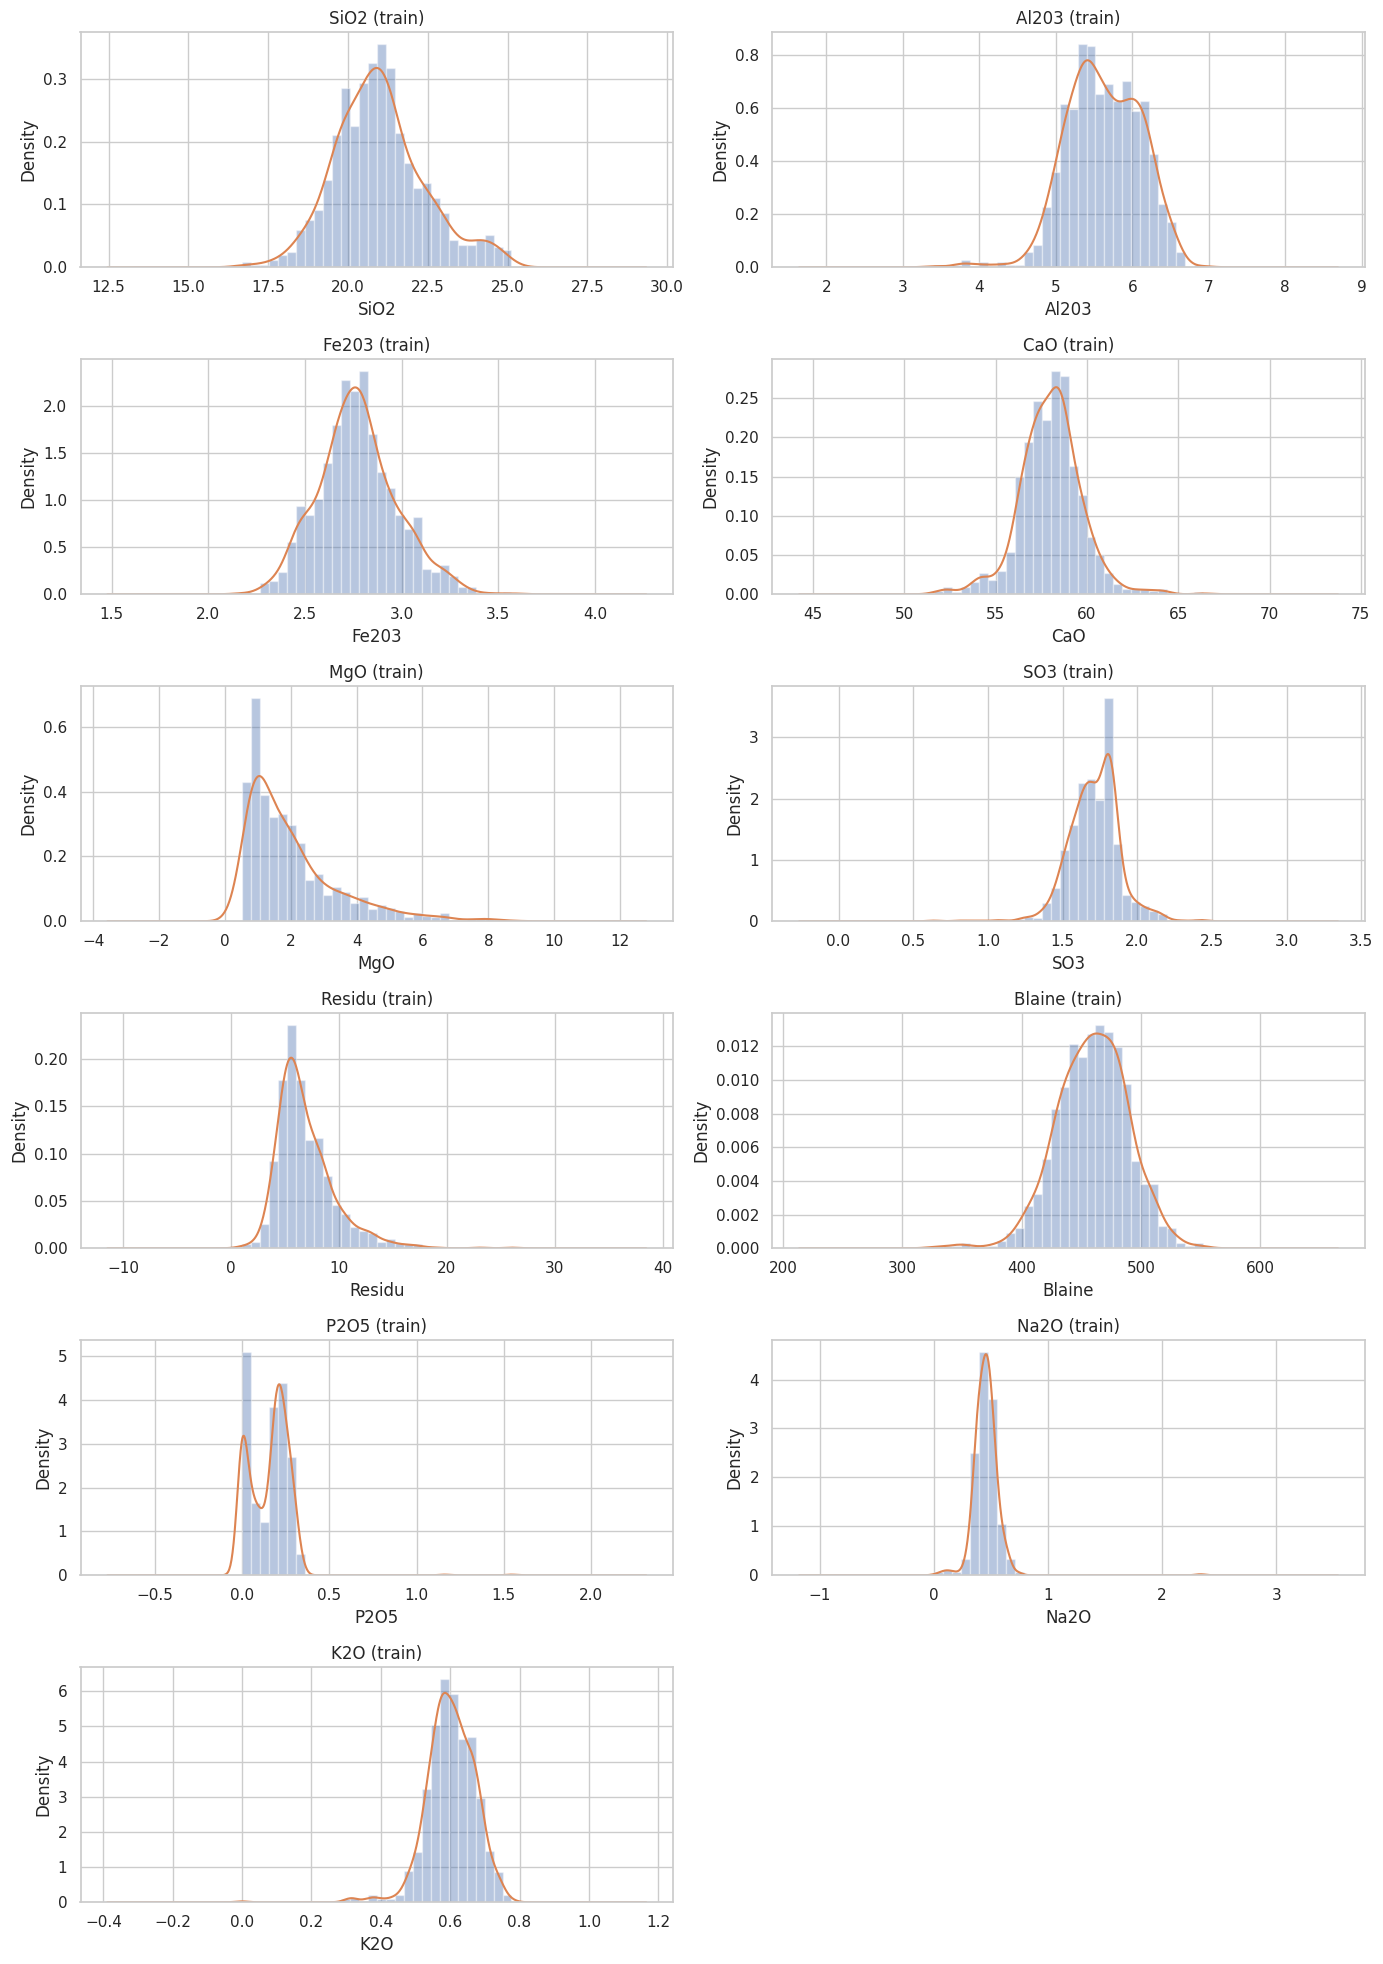

,Feature,Statistic,p-value,Conclusion
0,SiO2,0.982981,1.011209e-08,Not normal
1,Al203,0.981698,3.535210e-09,Not normal
2,Fe203,0.992296,1.281717e-04,Not normal
3,CaO,0.975653,4.210520e-11,Not normal
4,MgO,0.828689,6.324016e-30,Not normal
5,SO3,0.958132,2.450078e-15,Not normal
6,Residu,0.888277,5.958025e-25,Not normal
7,Blaine,0.990797,2.116603e-05,Not normal
8,P2O5,0.803252,1.222927e-31,Not normal
9,Na2O,0.648798,2.344129e-39,Not normal


In [13]:
fig, axes = grid_axes(len(FEATURES), row_height=3.3)
for ax, col in zip(axes, FEATURES):
    X_train_imputed[col].plot(kind="hist", bins=30, density=True, alpha=0.4, ax=ax)
    X_train_imputed[col].plot(kind="kde", ax=ax)
    ax.set_title(f"{col} (train)")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

shapiro_result = pd.DataFrame([
    {"Feature": c, **dict(zip(["Statistic", "p-value"], shapiro(X_train_imputed[c])))}
    for c in FEATURES
])
shapiro_result["Conclusion"] = np.where(shapiro_result["p-value"] > 0.05, "Normal", "Not normal")
shapiro_result

### 5.2 Target over time and seasonality

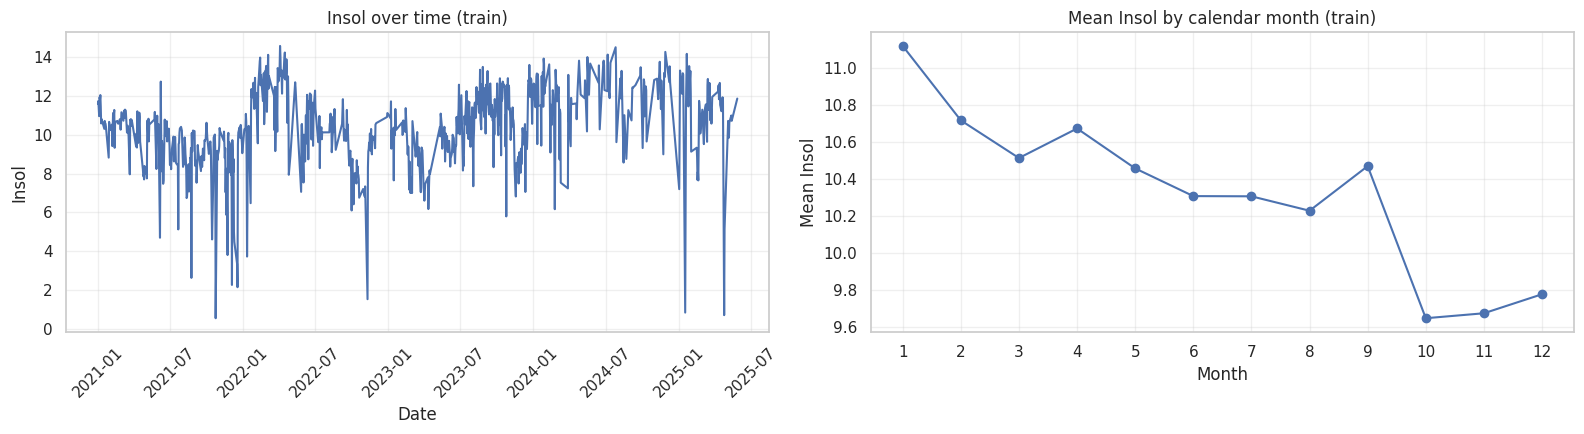

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(dates_train, y_train)
axes[0].set_title("Insol over time (train)")
axes[0].set_xlabel("Date"); axes[0].set_ylabel("Insol")
axes[0].tick_params(axis="x", rotation=45)

monthly_mean = y_train.groupby(dates_train.dt.month).mean()
axes[1].plot(monthly_mean.index, monthly_mean.values, marker="o")
axes[1].set_xticks(range(1, 13))
axes[1].set_title("Mean Insol by calendar month (train)")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Mean Insol")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 Correlation with Insol

Pearson correlation on the levels, and again after first-differencing. A feature that is correlated only
because both series share a trend loses correlation after differencing; one that keeps it is related
day to day as well.

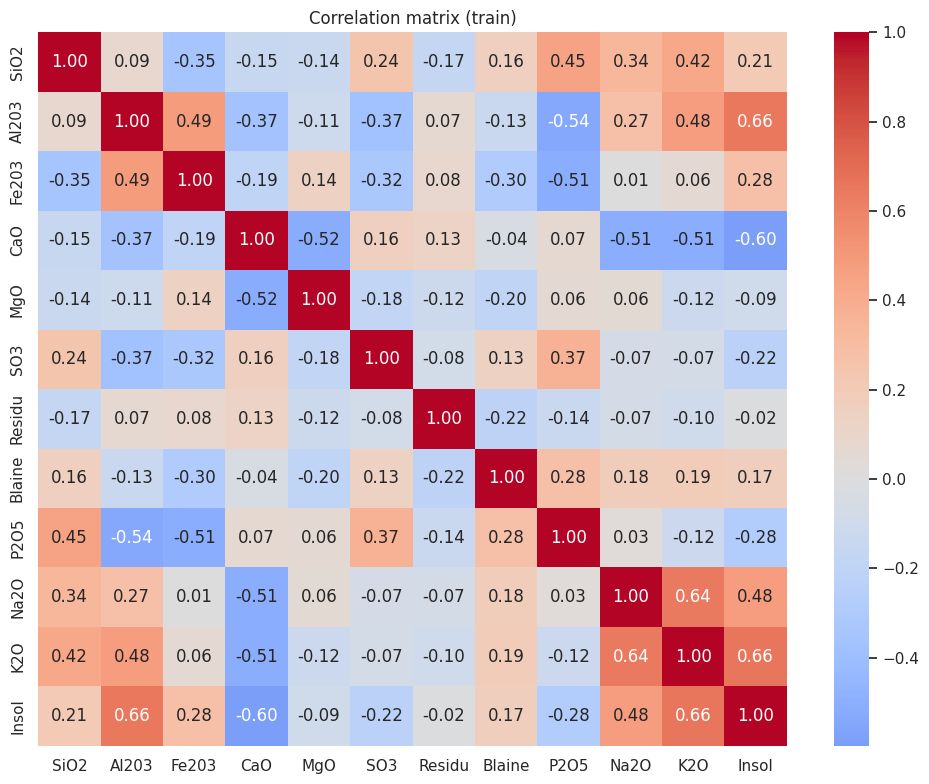

,corr (level),corr (differenced),change
K2O,0.657,0.506,-0.151
Al203,0.656,0.460,-0.196
CaO,-0.597,-0.600,-0.003
Na2O,0.477,0.399,-0.078
P2O5,-0.282,-0.068,0.213
Fe203,0.282,0.161,-0.120
SO3,-0.224,-0.181,0.043
SiO2,0.210,0.435,0.225
Blaine,0.169,0.436,0.268
MgO,-0.094,-0.004,0.091


In [15]:
train_frame = X_train_imputed.copy()
train_frame[TARGET] = y_train

corr = train_frame.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (train)")
plt.tight_layout()
plt.show()

corr_diff = train_frame.diff().corr()
level_vs_diff = pd.DataFrame({
    "corr (level)": corr[TARGET],
    "corr (differenced)": corr_diff[TARGET],
}).drop(index=TARGET)
level_vs_diff["change"] = level_vs_diff["corr (differenced)"] - level_vs_diff["corr (level)"]
level_vs_diff.sort_values("corr (level)", key=np.abs, ascending=False).round(3)

### 5.4 Multicollinearity (VIF)

Rule of thumb: VIF < 5 is fine, 5 to 10 deserves attention, > 10 is high multicollinearity.

In [16]:
vif = pd.DataFrame({
    "Feature": FEATURES,
    "VIF": [variance_inflation_factor(X_train_imputed.values, i) for i in range(len(FEATURES))],
}).sort_values("VIF", ascending=False).reset_index(drop=True)
vif

,Feature,VIF
0,CaO,3.078953
1,Al203,2.867591
2,K2O,2.853588
3,P2O5,2.404700
4,MgO,2.374774
5,SiO2,2.214918
6,Na2O,1.917562
7,Fe203,1.780260
8,SO3,1.365660
9,Blaine,1.353366


### 5.5 Feature vs. Insol scatter and autocorrelation

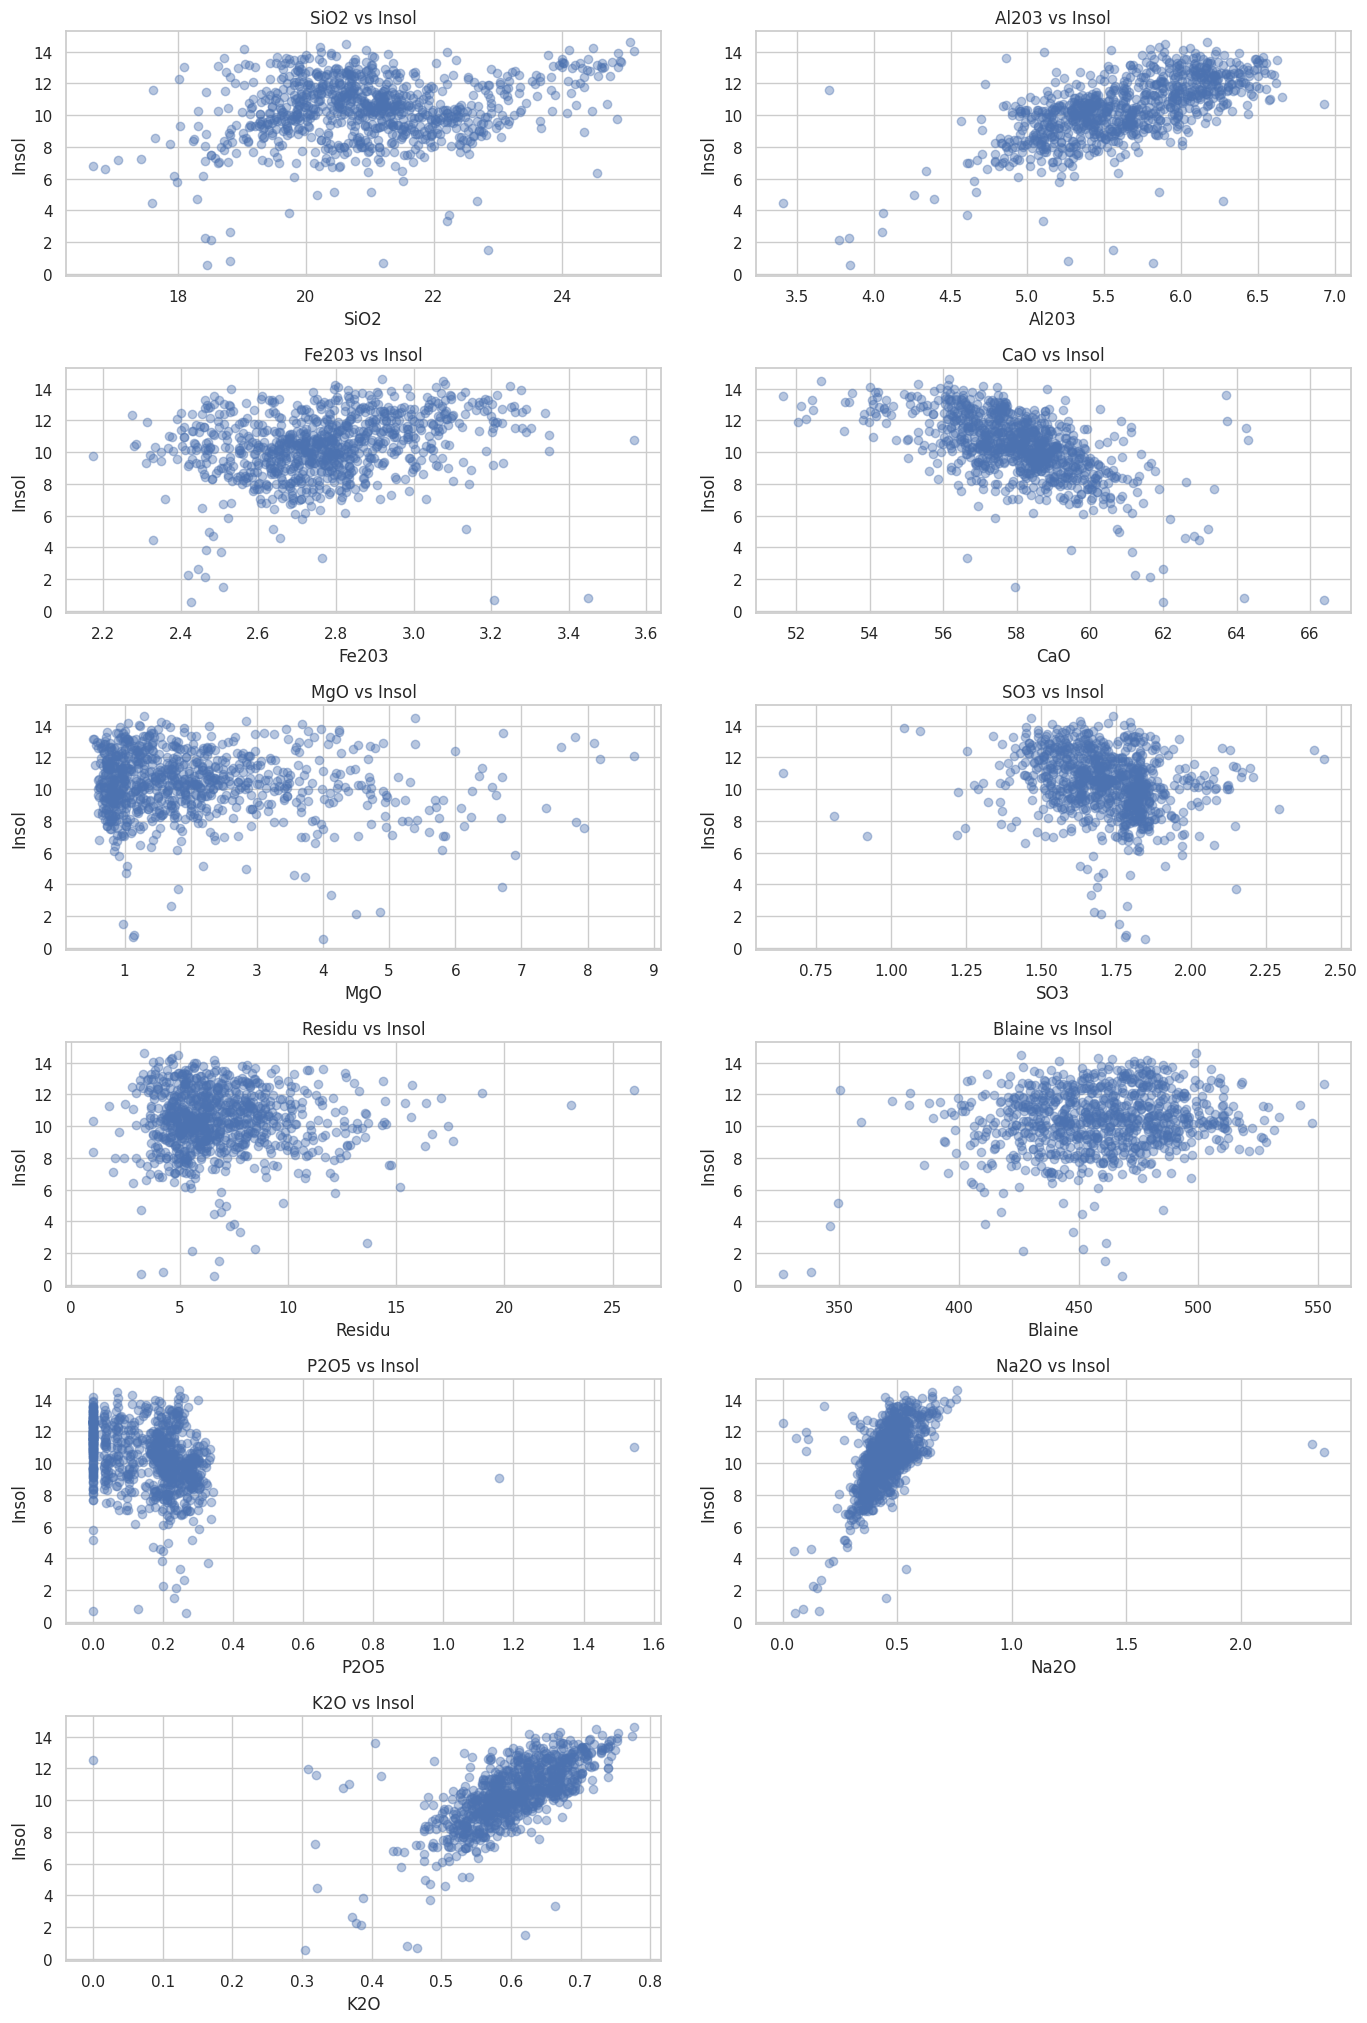

In [17]:
fig, axes = grid_axes(len(FEATURES), row_height=3.4)
for ax, col in zip(axes, FEATURES):
    ax.scatter(X_train_imputed[col], y_train, alpha=0.4)
    ax.set_title(f"{col} vs Insol")
    ax.set_xlabel(col); ax.set_ylabel("Insol")
plt.tight_layout()
plt.show()

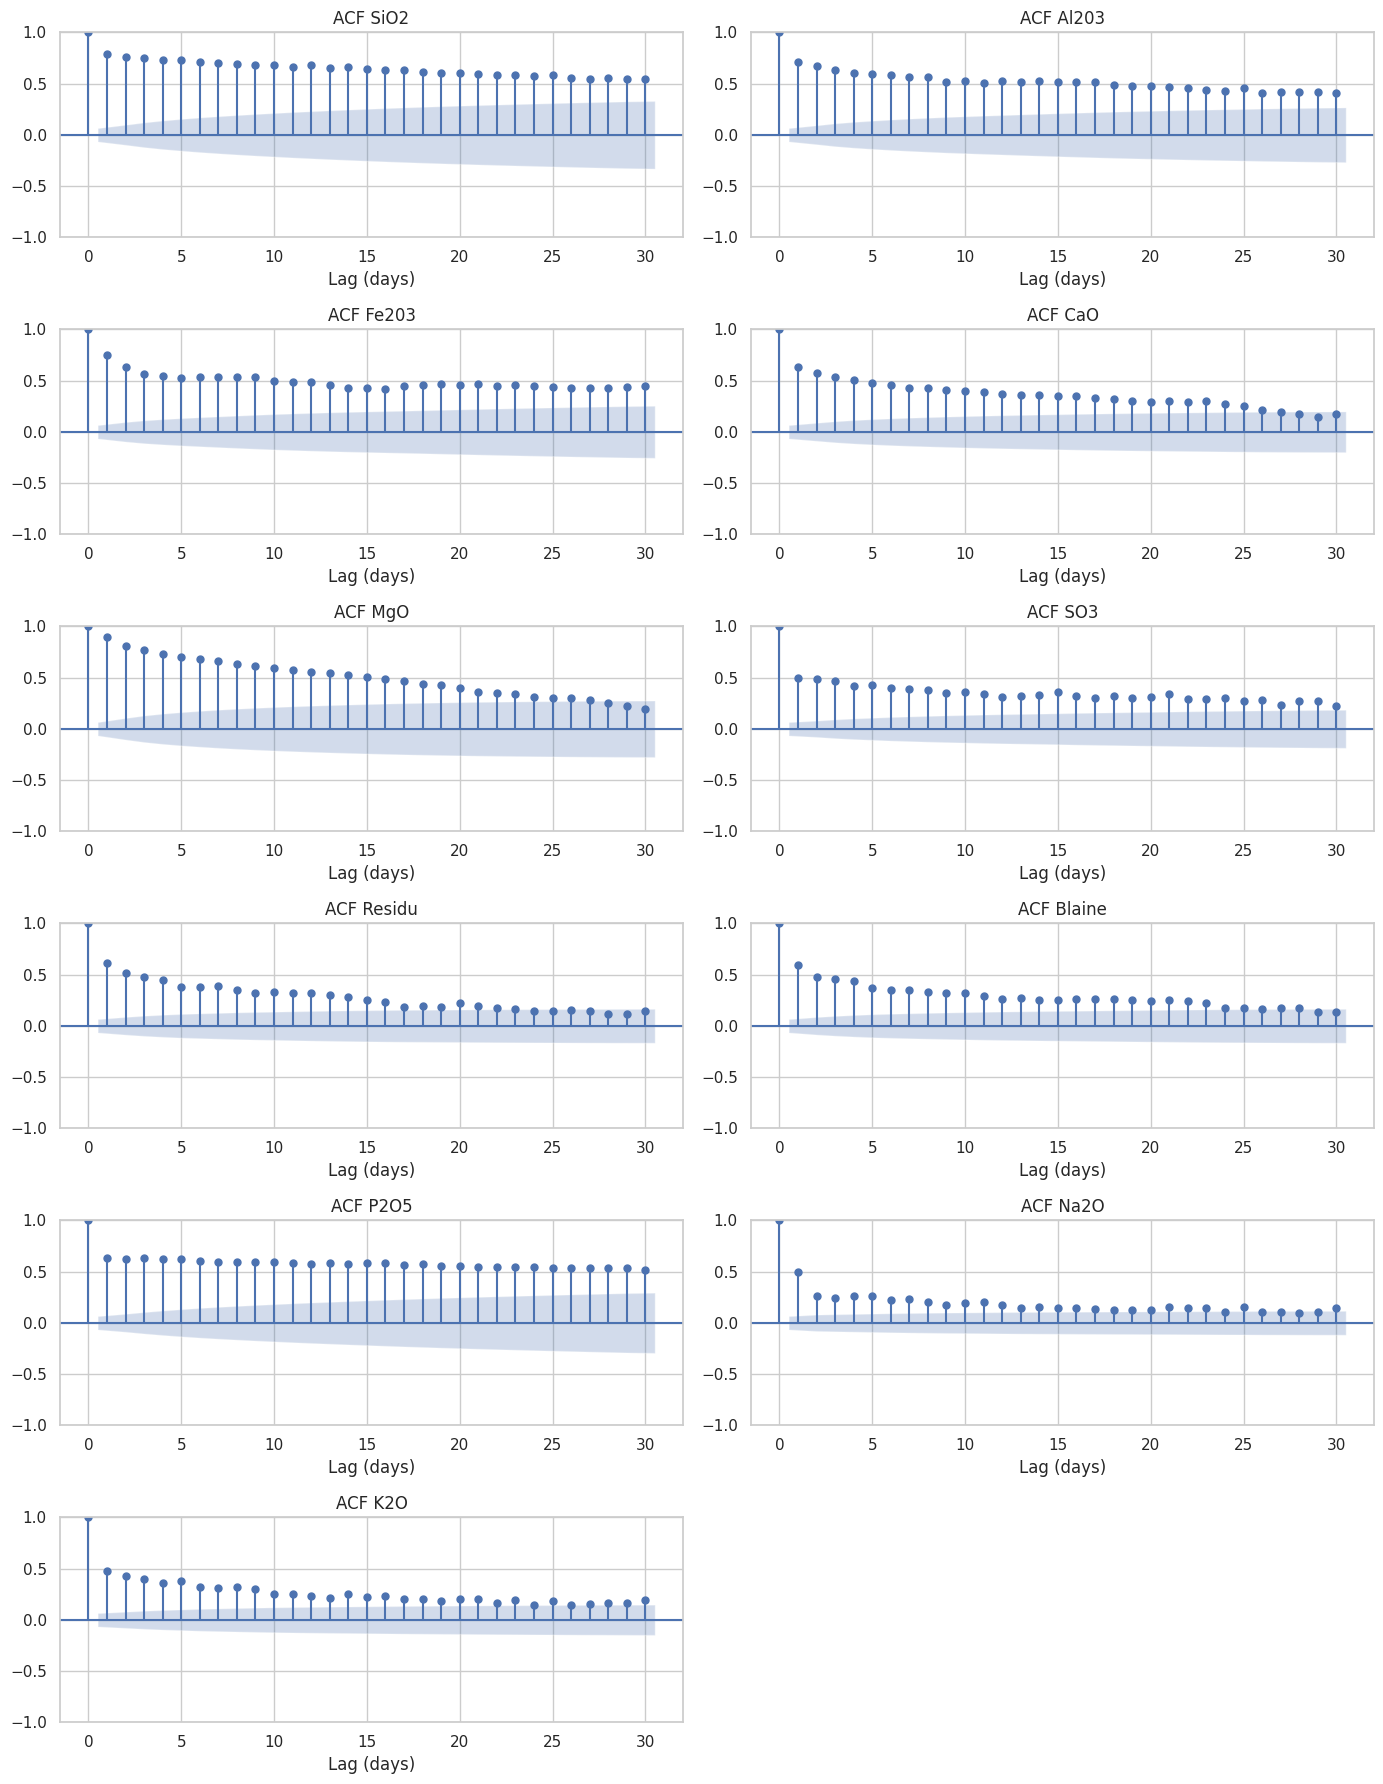

In [18]:
fig, axes = grid_axes(len(FEATURES), row_height=3.0)
for ax, col in zip(axes, FEATURES):
    plot_acf(X_train_imputed[col].dropna(), lags=30, ax=ax)
    ax.set_title(f"ACF {col}")
    ax.set_xlabel("Lag (days)")
plt.tight_layout()
plt.show()

## 6. Feature engineering and model selection

Lags of the 8 core oxides at 1, 2, 3, 5 and 10 days give `11 + 8 x 5 = 51` features. Lags are built on the
concatenated (imputed) train + test series: the first test rows legitimately use the end of train as their
history, because `shift()` only looks backwards. The first `MAX_LAG` train rows have no full history and are dropped.

In [19]:
X_all_imputed = pd.concat([X_train_imputed, X_test_imputed], ignore_index=True)
X_all_fe = add_lags(X_all_imputed)
n_train = len(X_train_imputed)

X_train_fe = X_all_fe.iloc[MAX_LAG:n_train].reset_index(drop=True)
y_train_fe = y_train.iloc[MAX_LAG:].reset_index(drop=True)
X_test_fe = X_all_fe.iloc[n_train:].reset_index(drop=True)
y_test_fe = y_test.reset_index(drop=True)

assert list(X_train_fe.columns) == list(X_test_fe.columns)
assert X_train_fe.isna().sum().sum() == 0 and X_test_fe.isna().sum().sum() == 0

print("X_train_fe:", X_train_fe.shape, "| X_test_fe:", X_test_fe.shape)

X_train_fe: (888, 51) | X_test_fe: (225, 51)


**Model selection** uses chronological cross-validation (`TimeSeriesSplit`) **on train only**.
Primary metric: MAE (in % Insol); RMSE and R² are reported alongside.

In [20]:
tscv = TimeSeriesSplit(n_splits=CV_SPLITS)

cv_rows = []
for name, model in candidate_models().items():
    print(f"CV: {name}")
    s = cross_validate(model, X_train_fe, y_train_fe, cv=tscv,
                       scoring={"mae": "neg_mean_absolute_error",
                                "rmse": "neg_root_mean_squared_error", "r2": "r2"})
    cv_rows.append({"Model": name, "MAE_CV": -s["test_mae"].mean(),
                    "RMSE_CV": -s["test_rmse"].mean(), "R2_CV": s["test_r2"].mean()})

cv_results = pd.DataFrame(cv_rows).sort_values("MAE_CV").reset_index(drop=True)
cv_results

CV: Linear Regression
CV: Ridge
CV: Lasso
CV: ElasticNet
CV: Decision Tree
CV: Random Forest
CV: Extra Trees
CV: Gradient Boosting
CV: Hist Gradient Boosting


,Model,MAE_CV,RMSE_CV,R2_CV
0,Lasso,0.913793,1.296112,0.404515
1,ElasticNet,0.924128,1.305223,0.398146
2,Ridge,0.951353,1.331964,0.376349
3,Linear Regression,0.951842,1.331822,0.376113
4,Gradient Boosting,1.029165,1.408349,0.401967
5,Extra Trees,1.068529,1.457778,0.365421
6,Random Forest,1.094801,1.490046,0.333935
7,Hist Gradient Boosting,1.161562,1.553714,0.272605
8,Decision Tree,1.437833,1.968028,-0.205195


## 7. Test evaluation (first and only look at the test set for model choice)

The model with the lowest CV MAE is fitted on train and compared with two naive baselines:
the train mean, and "yesterday's Insol".

In [21]:
best_name = cv_results.loc[0, "Model"]
print("Selected model (lowest CV MAE on train):", best_name)

best_model = clone(candidate_models()[best_name]).fit(X_train_fe, y_train_fe)
pred_best = best_model.predict(X_test_fe)

baseline_mean = np.full(len(y_test_fe), y_train_fe.mean())
baseline_previous = np.r_[y_train_fe.iloc[-1], y_test_fe.values[:-1]]     # yesterday's actual

pd.DataFrame([
    regression_metrics(best_name, y_test_fe, pred_best),
    regression_metrics("Baseline: train mean", y_test_fe, baseline_mean),
    regression_metrics("Baseline: previous Insol", y_test_fe, baseline_previous),
]).round(4)

Selected model (lowest CV MAE on train): Lasso


,Model,MAE,RMSE,R2,% days |err|<=1
0,Lasso,0.6463,0.8821,0.7434,80.8889
1,Baseline: train mean,1.7719,2.3275,-0.7864,34.6667
2,Baseline: previous Insol,1.1001,1.5723,0.1848,60.4444


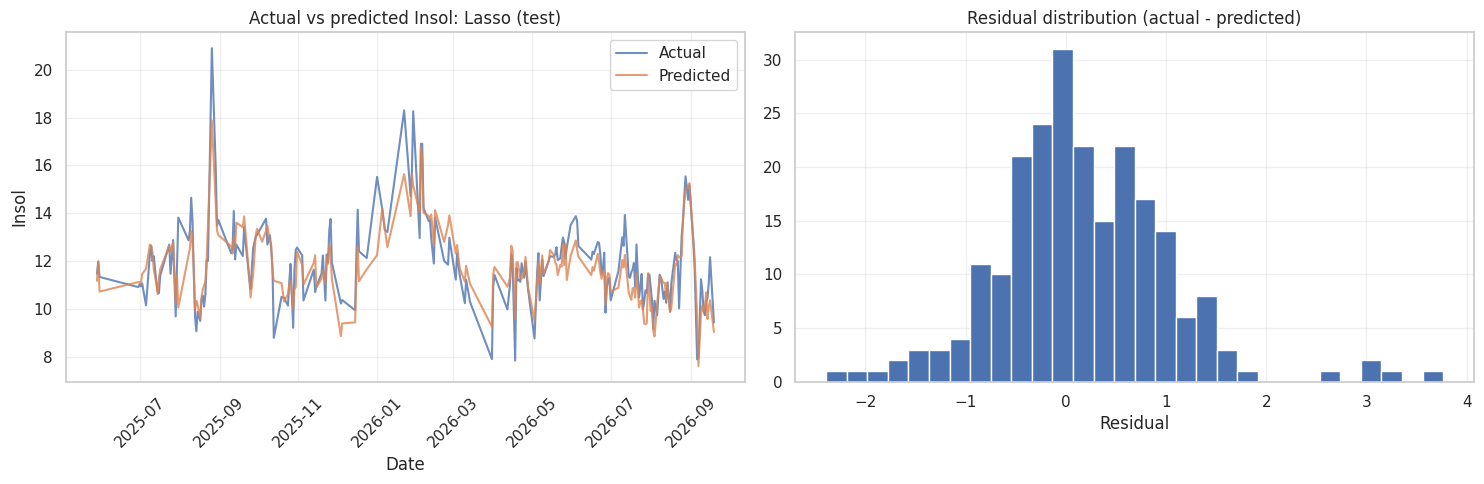

In [22]:
residual = y_test_fe.values - pred_best

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(dates_test, y_test_fe, label="Actual", alpha=0.8)
axes[0].plot(dates_test, pred_best, label="Predicted", alpha=0.8)
axes[0].set_title(f"Actual vs predicted Insol: {best_name} (test)")
axes[0].set_xlabel("Date"); axes[0].set_ylabel("Insol")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].hist(residual, bins=30)
axes[1].set_title("Residual distribution (actual - predicted)")
axes[1].set_xlabel("Residual")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.1 Residual bias by month

`residual = actual - prediction`. A positive monthly mean means the model under-predicts that month,
a negative one means it over-predicts. Blocks of same-signed months indicate **temporal drift**.

> This is exploratory. Do **not** use it to pick parameters.

Overall mean residual: +0.1673 (under-predicts on average)


,n,bias | Lasso,MAE | Lasso,RMSE | Lasso
Month,,,,
2025-05,3,0.309,0.309,0.395
2025-06,1,-0.210,0.210,0.210
2025-07,18,-0.011,0.567,1.029
2025-08,19,0.180,0.760,1.043
2025-09,12,-0.087,0.533,0.668
2025-10,16,-0.005,0.643,0.864
2025-11,13,0.083,0.575,0.739
2025-12,7,0.998,0.998,1.067
2026-01,8,1.315,1.340,1.891


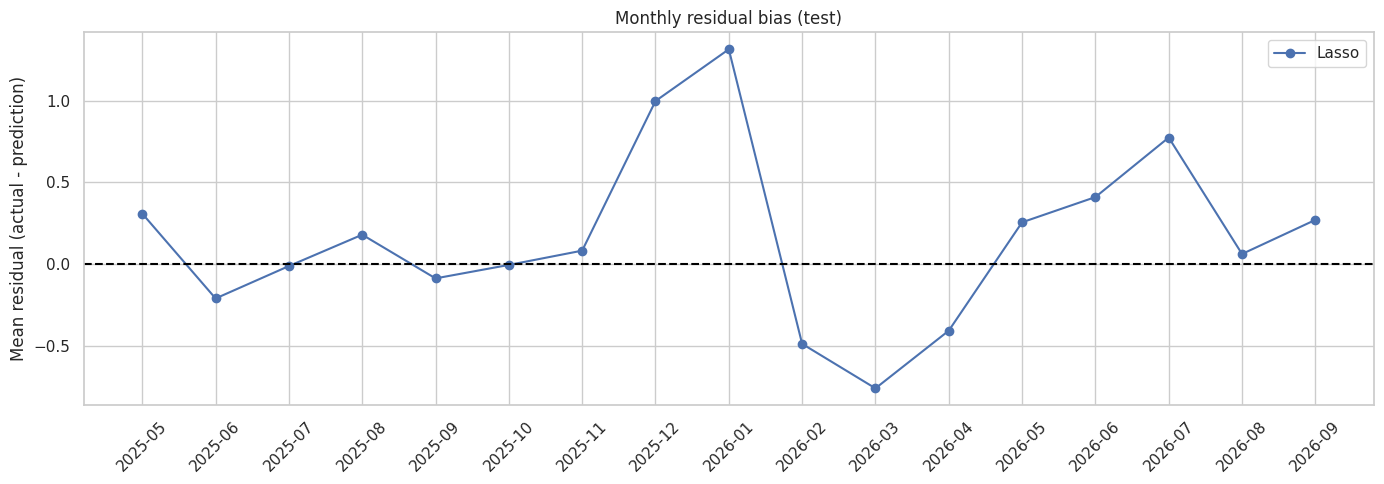

In [23]:
print(f"Overall mean residual: {residual.mean():+.4f}",
      "(under-predicts on average)" if residual.mean() > 0 else "(over-predicts on average)")

report_best = monthly_report(dates_test, y_test_fe, {best_name: pred_best})
display(report_best.round(3))
plot_monthly_bias(report_best, [best_name])

## 8. Residual correction with EWMA (baseline version)

If yesterday's actual Insol is known when predicting today, the recent residuals can be used to correct
the prediction: `final = model prediction + EWMA(past residuals)`. The residual of day *t* is only
available from day *t+1* onwards, so there is no leakage.

The EWMA `span` is chosen by `TimeSeriesSplit` **on train**. Small span = fast reaction, large span = smoother.

In [24]:
SPAN_CANDIDATES = [3, 5, 7, 10, 14, 21]

span_rows = []
for span in SPAN_CANDIDATES:
    mae_folds, rmse_folds = [], []
    for tr_idx, va_idx in TimeSeriesSplit(n_splits=CV_SPLITS).split(X_train_fe):
        X_tr, y_tr = X_train_fe.iloc[tr_idx], y_train_fe.iloc[tr_idx]
        X_va, y_va = X_train_fe.iloc[va_idx], y_train_fe.iloc[va_idx]

        fold_model = clone(best_model).fit(X_tr, y_tr)
        history = y_tr.values - fold_model.predict(X_tr)       # all known before the validation block
        pred_va = sequential_residual_correction(y_va.values, fold_model.predict(X_va),
                                                 span=span, initial_residuals=history)
        mae_folds.append(mean_absolute_error(y_va, pred_va))
        rmse_folds.append(np.sqrt(mean_squared_error(y_va, pred_va)))
    span_rows.append({"span": span, "MAE_CV": np.mean(mae_folds), "RMSE_CV": np.mean(rmse_folds)})

span_results = pd.DataFrame(span_rows).sort_values("MAE_CV").reset_index(drop=True)
best_span = int(span_results.loc[0, "span"])
display(span_results)
print("Best span (CV on train):", best_span)

,span,MAE_CV,RMSE_CV
0,7,0.739071,1.133334
1,10,0.739507,1.130762
2,14,0.744134,1.131803
3,5,0.745944,1.141589
4,21,0.753550,1.136348
5,3,0.773056,1.178546


Best span (CV on train): 7


In [25]:
train_residuals = y_train_fe.values - best_model.predict(X_train_fe)
pred_ewma_v1 = sequential_residual_correction(y_test_fe.values, pred_best,
                                              span=best_span, initial_residuals=train_residuals)

label_v1 = f"{best_name} + EWMA (span={best_span})"
comparison_v1 = pd.DataFrame([
    regression_metrics(best_name, y_test_fe, pred_best),
    regression_metrics(label_v1, y_test_fe, pred_ewma_v1),
    regression_metrics("Baseline: train mean", y_test_fe, baseline_mean),
    regression_metrics("Baseline: previous Insol", y_test_fe, baseline_previous),
]).round(4)
display(comparison_v1)

mae0, mae1 = comparison_v1.loc[0, "MAE"], comparison_v1.loc[1, "MAE"]
rmse0, rmse1 = comparison_v1.loc[0, "RMSE"], comparison_v1.loc[1, "RMSE"]
print(f"MAE  reduction: {(mae0 - mae1) / mae0 * 100:+.2f}%")
print(f"RMSE reduction: {(rmse0 - rmse1) / rmse0 * 100:+.2f}%")
print("EWMA lowers test MAE." if mae1 < mae0 else "EWMA does NOT lower test MAE: do not use it.")

,Model,MAE,RMSE,R2,% days |err|<=1
0,Lasso,0.6463,0.8821,0.7434,80.8889
1,Lasso + EWMA (span=7),0.5631,0.8070,0.7852,86.2222
2,Baseline: train mean,1.7719,2.3275,-0.7864,34.6667
3,Baseline: previous Insol,1.1001,1.5723,0.1848,60.4444


MAE  reduction: +12.87%
RMSE reduction: +8.51%
EWMA lowers test MAE.


,n,bias | no correction,MAE | no correction,RMSE | no correction,bias | EWMA,MAE | EWMA,RMSE | EWMA
Month,,,,,,,
2025-05,3,0.309,0.309,0.395,0.618,0.618,0.678
2025-06,1,-0.210,0.210,0.210,-0.309,0.309,0.309
2025-07,18,-0.011,0.567,1.029,0.099,0.571,1.027
2025-08,19,0.180,0.760,1.043,0.027,0.645,1.011
2025-09,12,-0.087,0.533,0.668,-0.099,0.583,0.684
2025-10,16,-0.005,0.643,0.864,0.032,0.669,0.883
2025-11,13,0.083,0.575,0.739,0.060,0.587,0.724
2025-12,7,0.998,0.998,1.067,0.506,0.548,0.662
2026-01,8,1.315,1.340,1.891,0.787,1.325,1.712


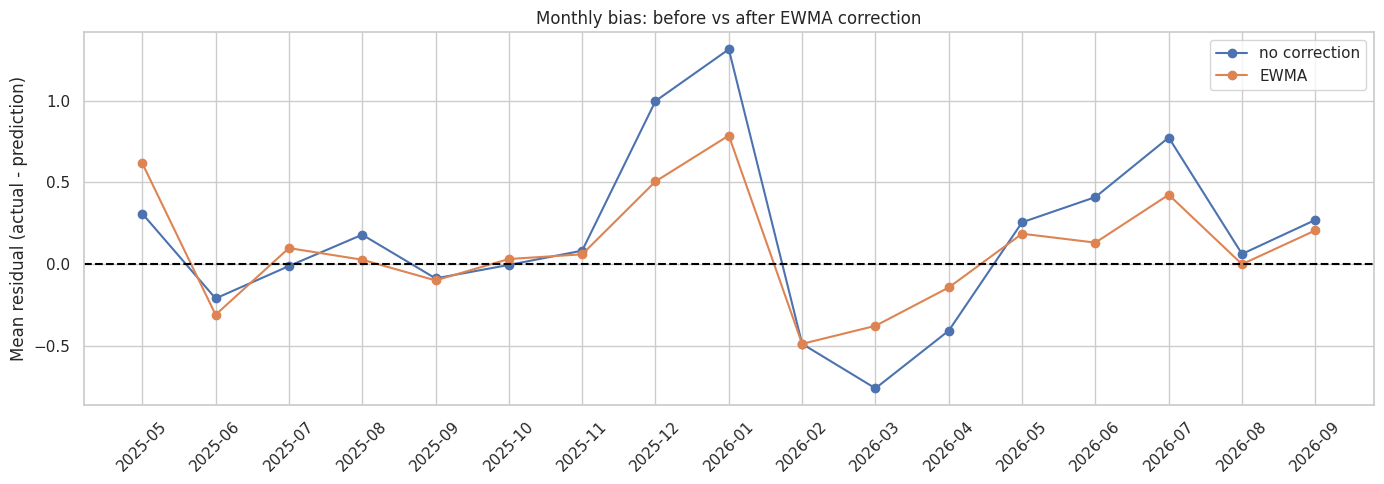

In [26]:
report_v1 = monthly_report(dates_test, y_test_fe, {"no correction": pred_best, "EWMA": pred_ewma_v1})
display(report_v1.round(3))
plot_monthly_bias(report_v1, ["no correction", "EWMA"], "Monthly bias: before vs after EWMA correction")

## 9. Tuning and improved residual correction

Four changes relative to section 8:

1. **Correction function.** `sequential_residual_correction` stores `actual - corrected prediction`, so for a constant bias *b* it only converges to *b/2*. `ewma_correction` uses the **raw** model residual and can close the full bias (proof below).
2. **Tuning** of Ridge / Lasso / ElasticNet with `TimeSeriesSplit` on train, and original features vs. original + lags.
3. **Out-of-fold residuals** to choose `span` and a shrinkage factor `k` (`k = 0` means "no correction", so not correcting is also a candidate).
4. **Significance tests** (Wilcoxon + block bootstrap) and **ACF of residuals** before vs. after.

`LAB_DELAY_DAYS` simulates lab latency: if the actual Insol is only known `n` days later, set `n`.

In [27]:
LAB_DELAY_DAYS = 0      # 0 = yesterday's actual Insol is known when predicting today

# Sanity check: model is always 1.0 too low, with a little noise
rng = np.random.default_rng(0)
p_sim = np.full(300, 5.0)
y_sim = 6.0 + rng.normal(0, 0.3, 300)

old_c = sequential_residual_correction(y_sim, p_sim, span=7) - p_sim
new_c = ewma_correction(y_sim - p_sim, span=7)

print("True bias                          : 1.00")
print(f"sequential_residual_correction     : {old_c[50:].mean():.2f}")
print(f"ewma_correction                    : {new_c[50:].mean():.2f}")

True bias                          : 1.00
sequential_residual_correction     : 0.49
ewma_correction                    : 0.99


### 9.1 Tune linear models

In [28]:
tscv_tune = TimeSeriesSplit(n_splits=CV_SPLITS)

tuning_rows, searches = [], {}
for name in TUNING_CANDIDATES:
    searches[name] = tune_linear(name, X_train_fe, y_train_fe, tscv_tune)
    tuning_rows.append({
        "Model": name,
        "MAE_CV": -searches[name].best_score_,
        "Best params": {k.replace("m__", ""): round(float(v), 5) for k, v in searches[name].best_params_.items()},
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("MAE_CV").reset_index(drop=True)
tuned_name = tuning_results.loc[0, "Model"]

if "Lasso" in cv_results["Model"].values:
    ref = cv_results.set_index("Model").loc["Lasso", "MAE_CV"]
    print(f"Reference: Lasso (alpha=0.01) MAE_CV = {ref:.4f}")
display(tuning_results)
print("Best linear family after tuning:", tuned_name)

Reference: Lasso (alpha=0.01) MAE_CV = 0.9138


,Model,MAE_CV,Best params
0,Lasso,0.894273,{'alpha': 0.04344}
1,ElasticNet,0.895267,"{'alpha': 0.04344, 'l1_ratio': 0.9}"
2,Ridge,0.951127,{'alpha': 1.74333}


Best linear family after tuning: Lasso


**Original features vs. original + lags.** Parsimony rule: use the lag set only if it improves CV MAE by at least 1 %.

In [29]:
cols_original = [c for c in X_train_fe.columns if "_lag" not in c]
cols_all = list(X_train_fe.columns)

search_original = tune_linear(tuned_name, X_train_fe[cols_original], y_train_fe, tscv_tune)
search_with_lags = tune_linear(tuned_name, X_train_fe[cols_all], y_train_fe, tscv_tune)
mae_original, mae_with_lags = -search_original.best_score_, -search_with_lags.best_score_

display(pd.DataFrame([
    {"Feature set": f"Original only ({len(cols_original)})", "MAE_CV": mae_original},
    {"Feature set": f"Original + lags ({len(cols_all)})", "MAE_CV": mae_with_lags},
]))

if mae_with_lags < 0.99 * mae_original:
    tuned_cols, tuned_search = cols_all, search_with_lags
    print("Selected: original + lags")
else:
    tuned_cols, tuned_search = cols_original, search_original
    print("Selected: original only (lags do not improve accuracy by > 1%)")

tuned_model = tuned_search.best_estimator_            # already fitted on all train
pred_tuned = tuned_model.predict(X_test_fe[tuned_cols])

print("Best parameters:", {k.replace("m__", ""): float(v) for k, v in tuned_search.best_params_.items()})
print(f"MAE_CV of the tuned model: {-tuned_search.best_score_:.4f}")

coef = getattr(tuned_model.named_steps["m"], "coef_", None)
if coef is not None:
    coef = pd.Series(coef, index=tuned_cols)
    print(f"Zero coefficients: {(coef == 0).sum()} of {len(coef)}")
    display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).to_frame("coefficient (z-scale)"))

,Feature set,MAE_CV
0,Original only (11),0.836299
1,Original + lags (51),0.894273


Selected: original only (lags do not improve accuracy by > 1%)
Best parameters: {'alpha': 0.002492021151378057}
MAE_CV of the tuned model: 0.8363
Zero coefficients: 0 of 11


,coefficient (z-scale)
CaO,-1.059558
MgO,-0.608847
Al203,0.535367
K2O,0.294941
Blaine,0.282790
Fe203,0.179741
SO3,-0.121522
P2O5,-0.101170
SiO2,0.095009
Residu,0.062871


### 9.2 Out-of-fold residuals, then choose `span` and `k`

Each `TimeSeriesSplit` fold trains on the past only and predicts the next block. Stitched together, these
blocks form an honest prediction series on which the correction is simulated day by day.
The **test set is not touched**.

In [30]:
y_arr = y_train_fe.values.astype(float)
X_tuned_train = X_train_fe[tuned_cols]

oof_pred = np.full(len(y_arr), np.nan)
for idx_tr, idx_va in tscv_tune.split(X_tuned_train):
    fold_model = clone(tuned_model).fit(X_tuned_train.iloc[idx_tr], y_arr[idx_tr])
    oof_pred[idx_va] = fold_model.predict(X_tuned_train.iloc[idx_va])

has_oof = ~np.isnan(oof_pred)
oof_resid = y_arr[has_oof] - oof_pred[has_oof]          # raw residuals in time order

print("OOF points      :", has_oof.sum())
print(f"OOF MAE (no correction): {np.mean(np.abs(oof_resid)):.4f}")
print(f"OOF bias               : {oof_resid.mean():.4f}")

OOF points      : 740
OOF MAE (no correction): 0.8363
OOF bias               : 0.3693


In [31]:
K_CANDIDATES = [0.0, 0.25, 0.5, 0.75, 1.0]

rows = []
for span in SPAN_CANDIDATES:
    c = ewma_correction(oof_resid, span, LAB_DELAY_DAYS)
    for k in K_CANDIDATES:
        err = oof_resid - k * c
        rows.append({"span": span, "k": k, "MAE_OOF": np.mean(np.abs(err)), "RMSE_OOF": np.sqrt(np.mean(err ** 2))})

span_k_results = pd.DataFrame(rows).sort_values("MAE_OOF").reset_index(drop=True)
span_best = int(span_k_results.loc[0, "span"])
k_best = float(span_k_results.loc[0, "k"])

print("Top 10 (span, k) by OOF MAE:")
display(span_k_results.head(10))
print(f"Selected: span={span_best}, k={k_best}")
print(f"OOF MAE: {np.mean(np.abs(oof_resid)):.4f} (no correction) -> {span_k_results.loc[0, 'MAE_OOF']:.4f}")
if k_best == 0:
    print("k = 0 was selected: EWMA does not help on the train data.")

Top 10 (span, k) by OOF MAE:


,span,k,MAE_OOF,RMSE_OOF
0,7,0.75,0.681637,1.148136
1,10,0.75,0.682506,1.145329
2,5,0.75,0.684566,1.156356
3,14,0.75,0.685552,1.147056
4,10,1.00,0.690404,1.156399
5,14,1.00,0.691792,1.152559
6,21,0.75,0.693244,1.153137
7,21,1.00,0.695060,1.154258
8,7,1.00,0.695133,1.167721
9,3,0.75,0.698395,1.182466


Selected: span=7, k=0.75
OOF MAE: 0.8363 (no correction) -> 0.6816


### 9.3 Test evaluation (single use)

The initial residual history for test is the **last out-of-fold** residuals of train, not in-sample ones.
The correction for day *t* only uses residuals up to *t - 1 - delay*.

In [32]:
y_te = y_test_fe.values.astype(float)

hist = oof_resid[-60:]                                   # honest history before the test period
test_resid_raw = y_te - pred_tuned
c_all = ewma_correction(np.r_[hist, test_resid_raw], span_best, LAB_DELAY_DAYS)
pred_final_v2 = pred_tuned + k_best * c_all[len(hist):]

rows = [
    regression_metrics(f"{best_name} (section 7)", y_test_fe, pred_best),
    regression_metrics(f"{tuned_name} tuned", y_test_fe, pred_tuned),
    regression_metrics(f"{tuned_name} tuned + EWMA (span={span_best}, k={k_best})", y_test_fe, pred_final_v2),
    regression_metrics(label_v1 + " [section 8]", y_test_fe, pred_ewma_v1),
    regression_metrics("Baseline: train mean", y_test_fe, baseline_mean),
    regression_metrics("Baseline: previous Insol", y_test_fe, baseline_previous),
]
results_v2 = pd.DataFrame(rows).round(4)
display(results_v2)

m0, m1, m2 = results_v2.loc[0, "MAE"], results_v2.loc[1, "MAE"], results_v2.loc[2, "MAE"]
print(f"MAE: {m0:.4f} -> tuned {m1:.4f} -> tuned + EWMA {m2:.4f}")
print(f"Total reduction vs section 7 model: {(m0 - m2) / m0 * 100:.2f}%")
print(f"Reduction from EWMA alone         : {(m1 - m2) / m1 * 100:.2f}%")

,Model,MAE,RMSE,R2,% days |err|<=1
0,Lasso (section 7),0.6463,0.8821,0.7434,80.8889
1,Lasso tuned,0.7487,1.0056,0.6665,74.2222
2,"Lasso tuned + EWMA (span=7, k=0.75)",0.5663,0.8311,0.7722,85.7778
3,Lasso + EWMA (span=7) [section 8],0.5631,0.8070,0.7852,86.2222
4,Baseline: train mean,1.7719,2.3275,-0.7864,34.6667
5,Baseline: previous Insol,1.1001,1.5723,0.1848,60.4444


MAE: 0.6463 -> tuned 0.7487 -> tuned + EWMA 0.5663
Total reduction vs section 7 model: 12.38%
Reduction from EWMA alone         : 24.36%


### 9.4 Is the improvement significant?

`d = |error without EWMA| - |error with EWMA|` per day (positive = EWMA better). Wilcoxon assumes independent days,
but residuals are autocorrelated, so its p-value tends to be optimistic. The **block bootstrap** (10-day blocks)
respects the dependence and is the better number to quote.

In [33]:
d = np.abs(y_te - pred_tuned) - np.abs(y_te - pred_final_v2)
print(f"Mean MAE difference (positive = EWMA better): {d.mean():.4f}")

try:
    print(f"Wilcoxon (one-sided): p = {wilcoxon(d, alternative='greater').pvalue:.4f}")
except ValueError as err:
    print("Wilcoxon not computable:", err)

lo, hi = block_bootstrap_ci(d, block=10)
print(f"Block-bootstrap 95% CI: [{lo:.4f}, {hi:.4f}]")
print("Significant improvement." if lo > 0 else "Interval includes 0: improvement not convincing.")

Mean MAE difference (positive = EWMA better): 0.1824
Wilcoxon (one-sided): p = 0.0000
Block-bootstrap 95% CI: [0.0960, 0.2828]
Significant improvement.


### 9.5 Residual autocorrelation before vs. after

If the correction captures temporal structure, residual autocorrelation should fall.
Ljung-Box: a small p-value means autocorrelation remains.

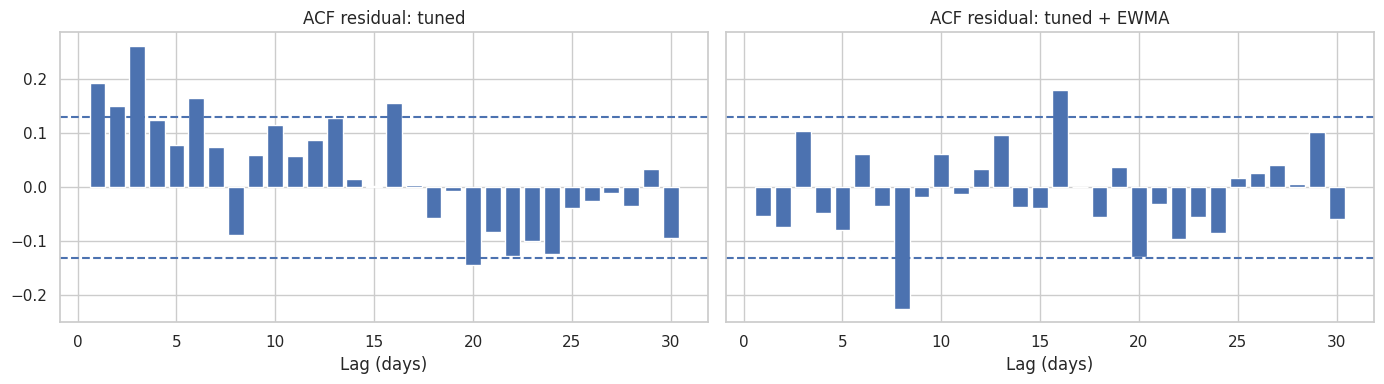

,Lag,p Ljung-Box (tuned),p Ljung-Box (tuned + EWMA)
0,5,1.930616e-06,0.272759
1,10,6.035944e-07,0.024902
2,20,6.175113e-07,0.012123


In [34]:
res_before, res_after = y_te - pred_tuned, y_te - pred_final_v2
conf = 1.96 / np.sqrt(len(y_te))

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, res, title in zip(axes, [res_before, res_after], ["ACF residual: tuned", "ACF residual: tuned + EWMA"]):
    ax.bar(range(1, 31), acf_manual(res, 30)[1:])
    ax.axhline(conf, ls="--"); ax.axhline(-conf, ls="--")
    ax.set_title(title); ax.set_xlabel("Lag (days)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Lag": [5, 10, 20],
    "p Ljung-Box (tuned)": list(ljung_box(res_before).values()),
    "p Ljung-Box (tuned + EWMA)": list(ljung_box(res_after).values()),
})

,n,bias | Lasso,MAE | Lasso,RMSE | Lasso,bias | tuned,MAE | tuned,RMSE | tuned,bias | tuned + EWMA,MAE | tuned + EWMA,RMSE | tuned + EWMA
Month,,,,,,,,,,
2025-05,3,0.309,0.309,0.395,0.473,0.473,0.508,0.383,0.383,0.462
2025-06,1,-0.210,0.210,0.210,0.016,0.016,0.016,-0.170,0.170,0.170
2025-07,18,-0.011,0.567,1.029,0.206,0.639,1.233,0.218,0.672,1.252
2025-08,19,0.180,0.760,1.043,0.402,0.818,1.173,0.035,0.712,1.156
2025-09,12,-0.087,0.533,0.668,0.205,0.562,0.689,-0.066,0.610,0.707
2025-10,16,-0.005,0.643,0.864,0.428,0.762,0.929,0.182,0.651,0.875
2025-11,13,0.083,0.575,0.739,0.487,0.680,0.842,0.165,0.597,0.718
2025-12,7,0.998,0.998,1.067,1.055,1.055,1.153,0.322,0.473,0.603
2026-01,8,1.315,1.340,1.891,1.755,1.755,2.227,0.745,1.283,1.678


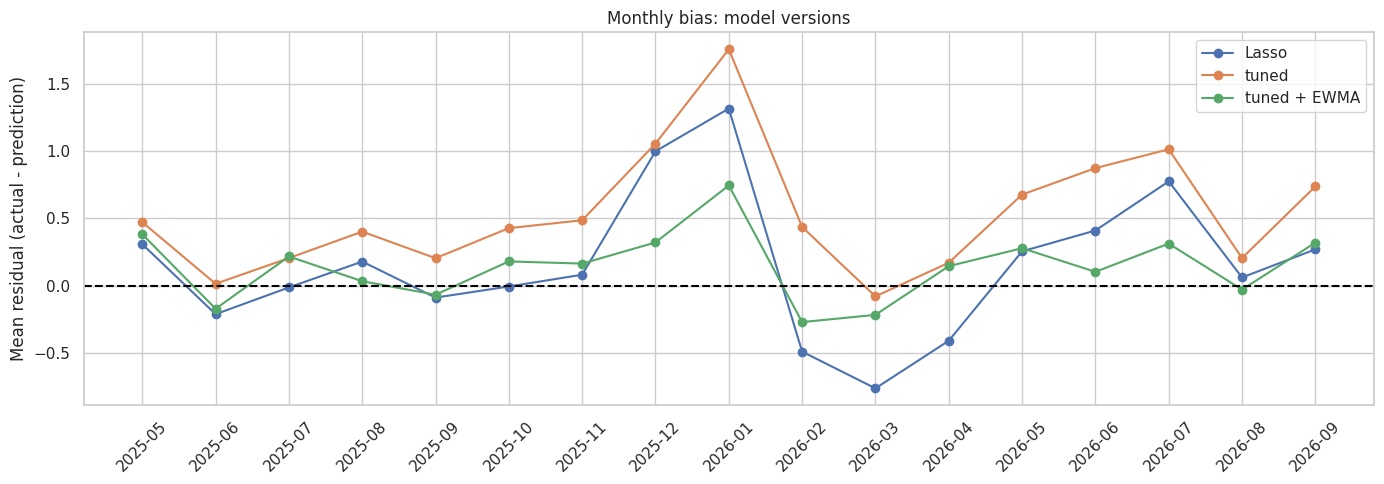

In [36]:
report_v2 = monthly_report(dates_test, y_test_fe, {
    f"{best_name}": pred_best, "tuned": pred_tuned, "tuned + EWMA": pred_final_v2})
display(report_v2.round(3))
plot_monthly_bias(report_v2, [best_name, "tuned", "tuned + EWMA"], "Monthly bias: model versions")

### 9.6 Notes for the report and for production

- Model, feature set, `alpha` / `l1_ratio`, `span` and `k` are all chosen on **train** (chronological CV and out-of-fold residuals). The test set is evaluated once.
- The monthly residual analyses are **exploratory**; never use them to choose parameters.
- EWMA correction is only valid if the previous days' actual Insol is known at prediction time. Set `LAB_DELAY_DAYS` accordingly and re-run section 9.
- For production: retrain on train + test, recompute out-of-fold residuals, retrain periodically.
- If the bootstrap interval in 9.4 includes 0, report that the EWMA improvement is **not proven significant**.

## 10. Extra experiments

**A. Insol lags as features** (so far Insol only enters through the EWMA correction) and
**B. periodic retraining** (walk-forward, refit every `REFIT_EVERY` rows, mimicking new data arriving).
Same evaluation rules as above: one-step-ahead, previous days' actual Insol is known.
Both use `Lasso(alpha=0.01)` + the baseline EWMA (`EWMA_SPAN`).

In [35]:
INSOL_LAGS = [1, 2, 3, 5]
REFIT_EVERY = 30            # about one month of daily rows

y_all = df[TARGET].astype(float).reset_index(drop=True)
n_all = len(X_all_imputed)
assert len(y_all) == n_all, "df and X_all_imputed must have the same length"

F_exp = X_all_fe.reset_index(drop=True).copy()
for L in INSOL_LAGS:
    F_exp[f"Insol_lag{L}"] = y_all.shift(L)

cols_base = list(X_train_fe.columns)
cols_insol = cols_base + [f"Insol_lag{L}" for L in INSOL_LAGS]


def run_walk_forward(columns, retrain):
    """Predict the whole test period. Returns (model only, model + EWMA)."""
    if retrain:
        chunks = [(s, min(s + REFIT_EVERY, n_all)) for s in range(n_train, n_all, REFIT_EVERY)]
    else:
        chunks = [(n_train, n_all)]

    raw_parts, ewma_parts = [], []
    for start, end in chunks:
        X_fit, y_fit = F_exp.iloc[MAX_LAG:start][columns], y_all.iloc[MAX_LAG:start]
        model = make_final_model("lasso").fit(X_fit, y_fit)
        history = y_fit.values - model.predict(X_fit)
        p = model.predict(F_exp.iloc[start:end][columns])
        raw_parts.append(p)
        ewma_parts.append(sequential_residual_correction(y_all.iloc[start:end].values, p,
                                                         span=EWMA_SPAN, initial_residuals=history))
    return np.concatenate(raw_parts), np.concatenate(ewma_parts)


y_true_test = y_all.iloc[n_train:].values
rows, ewma_by_config = [], {}
for set_name, columns in [("Base", cols_base), ("+ Insol lags", cols_insol)]:
    for retrain in [False, True]:
        raw_p, ewma_p = run_walk_forward(columns, retrain)
        tag = "periodic retrain" if retrain else "fixed (train only)"
        rows.append({**regression_metrics(f"{set_name} | {tag} | Lasso", y_true_test, raw_p),
                     "Max error": np.abs(y_true_test - raw_p).max()})
        rows.append({**regression_metrics(f"{set_name} | {tag} | Lasso + EWMA({EWMA_SPAN})", y_true_test, ewma_p),
                     "Max error": np.abs(y_true_test - ewma_p).max()})
        ewma_by_config[(set_name, retrain)] = ewma_p

rows.append(regression_metrics("Baseline: previous Insol", y_true_test, y_all.iloc[n_train - 1:n_all - 1].values))
experiments = pd.DataFrame(rows).round(3)
display(experiments)

mae_base = np.mean(np.abs(y_true_test - ewma_by_config[("Base", True)]))
mae_lag = np.mean(np.abs(y_true_test - ewma_by_config[("+ Insol lags", True)]))
USE_INSOL_LAGS = bool(mae_lag < mae_base)
print(f"MAE with periodic retrain  Base: {mae_base:.3f} | + Insol lags: {mae_lag:.3f}")
print("USE_INSOL_LAGS =", USE_INSOL_LAGS)
print("(This choice looks at test data, so treat it as an indication, not proof.)")

,Model,MAE,RMSE,R2,% days |err|<=1,Max error
0,Base | fixed (train only) | Lasso,0.646,0.882,0.743,80.889,3.765
1,Base | fixed (train only) | Lasso + EWMA(7),0.563,0.807,0.785,86.222,3.777
2,Base | periodic retrain | Lasso,0.644,0.879,0.745,80.444,3.765
3,Base | periodic retrain | Lasso + EWMA(7),0.557,0.802,0.788,85.778,3.777
4,+ Insol lags | fixed (train only) | Lasso,0.578,0.824,0.776,84.000,3.594
5,+ Insol lags | fixed (train only) | Lasso + EW...,0.581,0.827,0.775,83.111,3.911
6,+ Insol lags | periodic retrain | Lasso,0.572,0.817,0.780,84.444,3.557
7,+ Insol lags | periodic retrain | Lasso + EWMA(7),0.574,0.823,0.776,83.556,3.877
8,Baseline: previous Insol,1.100,1.572,0.185,60.444,NaN


MAE with periodic retrain  Base: 0.557 | + Insol lags: 0.574
USE_INSOL_LAGS = False
(This choice looks at test data, so treat it as an indication, not proof.)


**C. Huber regression** (loss that is more robust to spikes), with all features and with the 8 core oxides only
(MgO, Residu and P2O5 dropped). Trained on train, tested on test, baseline EWMA with `EWMA_SPAN`.

In [37]:
cols_8 = [c for c in X_train_fe.columns if c not in ("MgO", "Residu", "P2O5")]
assert len(cols_8) == len(LAG_FEATURES) * (1 + len(LAG_LIST))

pred_lasso_ewma = sequential_residual_correction(
    y_test_fe.values, pred_best, span=EWMA_SPAN,
    initial_residuals=y_train_fe.values - best_model.predict(X_train_fe))

rows = [regression_metrics(f"{best_name} + EWMA({EWMA_SPAN})", y_test_fe, pred_lasso_ewma)]
for label, columns in [("all features", list(X_train_fe.columns)), ("8 oxides", cols_8)]:
    huber = make_final_model("huber").fit(X_train_fe[columns], y_train_fe)
    p_raw = huber.predict(X_test_fe[columns])
    p_ewma = sequential_residual_correction(
        y_test_fe.values, p_raw, span=EWMA_SPAN,
        initial_residuals=y_train_fe.values - huber.predict(X_train_fe[columns]))
    rows += [regression_metrics(f"Huber | {label}", y_test_fe, p_raw),
             regression_metrics(f"Huber + EWMA({EWMA_SPAN}) | {label}", y_test_fe, p_ewma)]

pd.DataFrame(rows).round(3)

,Model,MAE,RMSE,R2,% days |err|<=1
0,Lasso + EWMA(7),0.563,0.807,0.785,86.222
1,Huber | all features,0.641,0.870,0.751,80.889
2,Huber + EWMA(7) | all features,0.550,0.803,0.787,87.111
3,Huber | 8 oxides,0.755,1.004,0.668,73.333
4,Huber + EWMA(7) | 8 oxides,0.626,0.874,0.748,83.111


## 11. Final figure: actual vs. predicted

Model from section 7 + baseline EWMA with a fixed `EWMA_SPAN`.

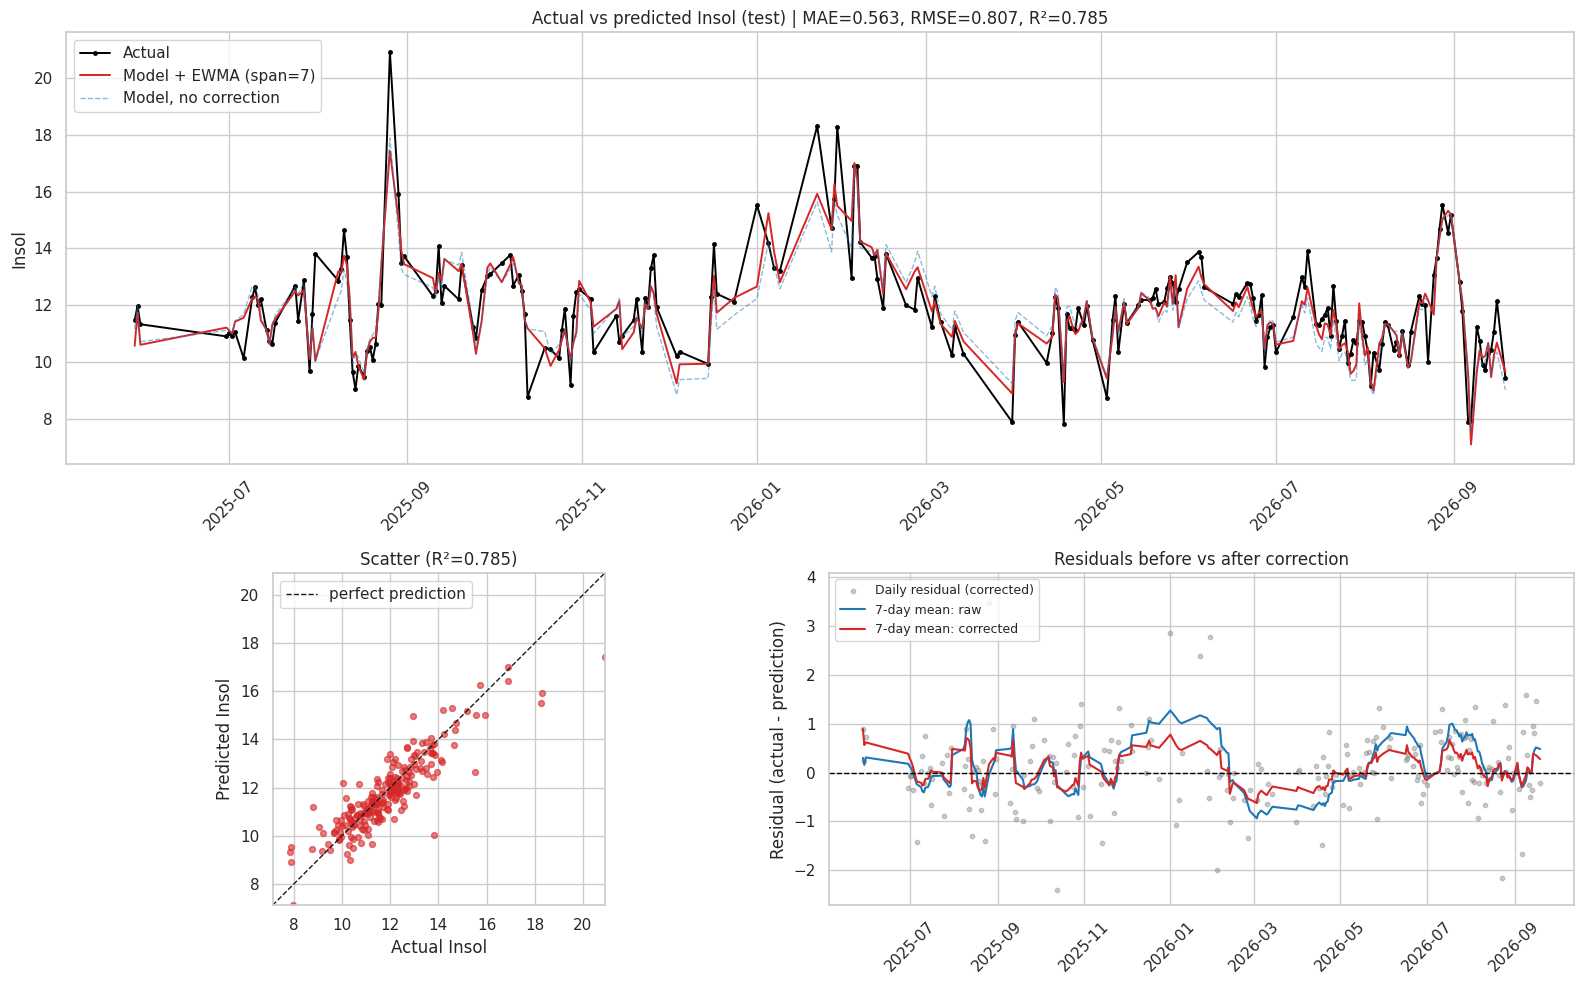

In [38]:
pred_final_v1 = sequential_residual_correction(
    y_test_fe.values, pred_best, span=EWMA_SPAN,
    initial_residuals=y_train_fe.values - best_model.predict(X_train_fe))

plot_actual_vs_predicted(dates_test, y_test_fe.values, pred_best, pred_final_v1, EWMA_SPAN,
                         save_as=OUTPUT_DIR / f"actual_vs_predicted_ewma_span{EWMA_SPAN}.png")

## 12. Inference

The production model is **retrained on all known days** (train + test + optional new data) and corrected with the
baseline EWMA (`EWMA_SPAN`). Lags and the correction come from the daily history, so predictions are most
accurate when `NEW_DAILY_FILE` contains every day up to *yesterday*.

> **Staleness warning.** If the last known day is more than 3 days before the target day, lags and EWMA are
> out of date and the prediction should be treated as a rough estimate.

In [39]:
def build_history(new_daily_file=None):
    """Imputed feature history, matching Insol history and the last known date."""
    X_hist = X_all_imputed.reset_index(drop=True).copy()
    y_hist = df[TARGET].astype(float).tolist()
    last_date = df["Tanggal"].max()

    if new_daily_file is not None:
        new = pd.read_excel(new_daily_file)
        new.columns = new.columns.str.strip()
        new["Tanggal"] = pd.to_datetime(new["Tanggal"])
        for col in FEATURES + [TARGET]:
            new[col] = pd.to_numeric(new[col], errors="coerce")
        new = apply_domain_rules(new)
        new = new[new["Tanggal"] > last_date].sort_values("Tanggal").reset_index(drop=True)
        assert new[TARGET].notna().all(), "Empty Insol in the new data"

        if len(new):
            X_hist = pd.concat([X_hist, impute(new, scaler_imp, knn_imputer)[FEATURES]], ignore_index=True)
            y_hist += new[TARGET].tolist()
            last_date = new["Tanggal"].max()
        print(f"New data added: {len(new)} days (until {last_date.date()})")

    return X_hist, y_hist, last_date


def fit_production_model(X_hist, y_hist, kind="lasso", use_insol_lags=False):
    """Fit on every known day; return (model, feature columns, in-sample residuals)."""
    y_full = pd.Series(y_hist, dtype=float)
    F = add_lags(X_hist)
    columns = list(X_train_fe.columns)
    if use_insol_lags:
        for L in INSOL_LAGS:
            F[f"Insol_lag{L}"] = y_full.shift(L)
        columns += [f"Insol_lag{L}" for L in INSOL_LAGS]

    X_fit, y_fit = F.iloc[MAX_LAG:][columns], y_full.iloc[MAX_LAG:]
    model = make_final_model(kind).fit(X_fit, y_fit)
    return model, columns, y_fit.values - model.predict(X_fit)


def predict_next_day(components, target_date, kind="lasso", use_insol_lags=False,
                     new_daily_file=None, actual_insol=None, span=EWMA_SPAN):
    """Predict Insol for one day from that day's composition (dict keyed by FEATURES).

    Missing values (np.nan) are imputed with the train KNN imputer.
    """
    X_hist, y_hist, last_date = build_history(new_daily_file)
    n_known = len(y_hist)

    x_new = impute(pd.DataFrame([components])[FEATURES], scaler_imp, knn_imputer)
    X_full = pd.concat([X_hist, x_new], ignore_index=True)
    y_full = pd.Series(y_hist + [np.nan])

    F = add_lags(X_full)
    columns = list(X_train_fe.columns)
    if use_insol_lags:
        for L in INSOL_LAGS:
            F[f"Insol_lag{L}"] = y_full.shift(L)
        columns += [f"Insol_lag{L}" for L in INSOL_LAGS]

    X_fit, y_fit = F.iloc[MAX_LAG:n_known][columns], y_full.iloc[MAX_LAG:n_known]
    model = make_final_model(kind).fit(X_fit, y_fit)
    residuals = y_fit.values - model.predict(X_fit)

    x_target = F.iloc[[-1]][columns]
    assert x_target.isna().sum().sum() == 0, "NaN in the target-day features"

    p_raw = float(model.predict(x_target)[0])
    p_final = float(sequential_residual_correction([np.nan], [p_raw], span=span,
                                                   initial_residuals=residuals)[0])
    gap = (pd.Timestamp(target_date) - last_date).days

    print("=" * 52)
    print(f"INSOL PREDICTION {target_date}  ({kind}{' + Insol lags' if use_insol_lags else ''} + EWMA {span})")
    print("=" * 52)
    print(f"Model only          : {p_raw:.3f}")
    print(f"EWMA correction     : {p_final - p_raw:+.3f}")
    print(f"Final prediction    : {p_final:.3f}")
    print(f"History ends        : {last_date.date()}  ({gap} days before target)")
    if gap > 3:
        print("WARNING: Insol history is stale. Provide NEW_DAILY_FILE so lags and EWMA are accurate.")
    if actual_insol is not None:
        print(f"Actual Insol        : {actual_insol:.3f}  (actual - prediction = {actual_insol - p_final:+.3f})")
    return p_final

### 12.1 Next-day prediction

In [40]:
# Illustrative values only: replace with the real composition of the target day.
# Use np.nan for anything not measured (imputed with the KNN imputer fitted on train).
example_components = {
    "SiO2": 20.3, "Al203": 6.1, "Fe203": 2.9, "CaO": 58.9, "MgO": 1.9,
    "SO3": 1.5, "Residu": 8.7, "Blaine": 458.0, "P2O5": np.nan, "Na2O": 0.41, "K2O": 0.57,
}

predict_next_day(example_components, target_date="2026-10-03",
                 kind="lasso", use_insol_lags=USE_INSOL_LAGS, new_daily_file=NEW_DAILY_FILE)

INSOL PREDICTION 2026-10-03  (lasso + EWMA 7)
Model only          : 10.719
EWMA correction     : +0.625
Final prediction    : 11.343
History ends        : 2026-09-19  (14 days before target)


11.34349339987327

### 12.2 Hourly (per-row) prediction from a QC CSV

Each row is predicted from **that hour's oxides + the daily lag history + the EWMA correction** (identical for
all hours of the day). A row's value means *"the daily Insol to expect if the whole day looked like this hour"*,
not an hourly Insol. Compare with the lab value only through the **mean** of the rows.

Two modes:

- `"8_oxides"`: uses only the 8 core oxides; only rows where all 8 are present are predicted.
- `"all_features"`: uses all 11 columns; rows with at least 8 of 11 present are predicted and the rest are KNN-imputed.

The source CSV is **never overwritten**; the result is written to a new file.

In [41]:
def predict_hourly(csv_path, output_path, mode="8_oxides", new_daily_file=None, span=EWMA_SPAN):
    if mode not in ("8_oxides", "all_features"):
        raise ValueError("mode must be '8_oxides' or 'all_features'")
    needed = LAG_FEATURES if mode == "8_oxides" else FEATURES
    columns = (list(X_train_fe.columns) if mode == "all_features"
               else [c for c in X_train_fe.columns if c not in ("MgO", "Residu", "P2O5")])

    # 1) train Huber on the whole daily history; EWMA correction from its residuals
    X_hist, y_hist, last_date = build_history(new_daily_file)
    F_hist = add_lags(X_hist[needed])
    X_fit, y_fit = F_hist.iloc[MAX_LAG:][columns], pd.Series(y_hist).iloc[MAX_LAG:]
    model = make_final_model("huber").fit(X_fit, y_fit)
    correction = float(sequential_residual_correction(
        [np.nan], [0.0], span=span, initial_residuals=y_fit.values - model.predict(X_fit))[0])

    # 2) read and clean the hourly CSV
    q = pd.read_csv(csv_path)
    q.columns = q.columns.str.strip()
    q = q.rename(columns={"Al2O3": "Al203", "Fe2O3": "Fe203"})
    q["Waktu"] = pd.to_datetime(q["SamplingLocalTime"])

    missing_cols = [c for c in needed if c not in q.columns]
    assert not missing_cols, f"Columns missing from the CSV: {missing_cols}"
    for col in needed:
        q[col] = pd.to_numeric(q[col], errors="coerce")
    q = apply_domain_rules(q)

    usable = q[needed].notna().sum(axis=1) >= 8
    print(f"CSV rows: {len(q)} | predicted: {usable.sum()} | skipped: {(~usable).sum()}")

    Q = q.loc[usable].reset_index(drop=True)
    Q_feat = (Q[needed] if mode == "8_oxides"
              else impute(q[FEATURES], scaler_imp, knn_imputer).loc[usable].reset_index(drop=True))

    # 3) features per row = that hour's oxides + the daily lags (same for every hour of the day)
    lag_values = {f"{k}_lag{L}": X_hist[k].iloc[-L] for k in LAG_FEATURES for L in LAG_LIST}
    X_row = pd.concat([Q_feat, pd.DataFrame([lag_values] * len(Q_feat), index=Q_feat.index)], axis=1)[columns]
    assert not X_row.isna().any().any(), "NaN in the row features"

    p_model = model.predict(X_row)
    p_final = p_model + correction

    # 4) write result next to the original columns, never over the source file
    out = q.copy()
    out["Prediction"] = np.nan
    out.loc[usable, "Prediction"] = p_final
    out.to_csv(output_path, index=False)

    result = Q[["Waktu"] + needed].copy()
    result["Waktu"] = result["Waktu"].dt.strftime("%H:%M")
    result["Pred_Model"], result["Pred_Final"] = p_model, p_final

    gap = (Q["Waktu"].dt.normalize().iloc[0] - last_date).days
    print(f"\nEWMA correction ({span})        : {correction:+.3f}")
    print(f"Mean of row predictions         : {p_final.mean():.3f}")
    print(f"Median / min / max              : {np.median(p_final):.3f} / {p_final.min():.3f} / {p_final.max():.3f}")
    print(f"History ends                    : {last_date.date()} ({gap} days before the CSV day)")
    if gap > 3:
        print("WARNING: Insol history is stale. Provide NEW_DAILY_FILE.")
    print("Saved to:", output_path)
    return result

In [42]:
if HOURLY_CSV.exists():
    hourly_result = predict_hourly(HOURLY_CSV, OUTPUT_DIR / f"{HOURLY_CSV.stem}_predicted.csv",
                                   mode="8_oxides", new_daily_file=NEW_DAILY_FILE)
    display(hourly_result.round(3))
else:
    print(f"{HOURLY_CSV} not found: skipping hourly prediction.")

data/QC_hourly.csv not found: skipping hourly prediction.


## 13. Save the model (optional)

Stores everything needed to predict later without re-running the notebook (model, imputer, column order, lag
settings, correction history, last 10 days of features).

In [43]:
X_hist, y_hist, last_date = build_history(NEW_DAILY_FILE)
final_model, final_columns, final_residuals = fit_production_model(X_hist, y_hist, "lasso", USE_INSOL_LAGS)

bundle = {
    "model": final_model,
    "scaler_imp": scaler_imp,
    "imputer": knn_imputer,
    "features": FEATURES,
    "columns": final_columns,
    "lag_features": LAG_FEATURES,
    "lag_list": LAG_LIST,
    "use_insol_lags": USE_INSOL_LAGS,
    "span": EWMA_SPAN,
    "residual_history": final_residuals,
    "recent_features": X_hist.tail(MAX_LAG).reset_index(drop=True),
    "last_date": str(last_date.date()),
}
model_path = OUTPUT_DIR / f"model_lasso_ewma{EWMA_SPAN}.joblib"
joblib.dump(bundle, model_path)
print("Saved:", model_path)

Saved: outputs/model_lasso_ewma7.joblib
